# AB_vieillissement_fabrication — fabrication, remplacements et réservoir sur la vie du véhicule

## Objet

Le notebook de couplage ne compte que la phase d'usage, sur la vie d'une pile. Ici on ajoute :

1. la **fabrication des composants qui vieillissent** : stack de la pile, stack de l'électrolyseur et réservoir, à partir des résultats Brightway (ecoinvent 3.11 cut-off, EF 3.1). Les auxiliaires (BOP) ne vieillissent pas dans le modèle : ils sont hors périmètre ;
2. les **remplacements** de stacks que le vieillissement impose pendant la vie du véhicule ;
3. le **vieillissement du réservoir** : la perméation d'hydrogène augmente avec l'âge.

L'unité fonctionnelle reste **1 km parcouru**, en moyenne sur la vie du véhicule :

$$\bar I_{km}=\underbrace{\frac{1}{L}\int_0^{L}\big(m_{FC}(t)+m_{perm}(t)\big)\,I_{kg}(t)\,dt}_{\text{usage}}+\underbrace{\frac{n_{FC}\,F_{stack,FC}+n_{res}\,F_{res}}{L_{km}}}_{\text{stacks de pile et réservoir}}+\underbrace{\bar m\,\frac{n_{WE}\,s\,F_{stack,WE}}{M_{H_2,L}}}_{\text{stacks d'électrolyseur}}$$

avec $L$ la vie du véhicule (ans), $L_{km}$ la distance correspondante, $n_{FC}$ le nombre de stacks de pile, $n_{WE}$ le nombre de stacks d'électrolyseur, $M_{H_2,L}$ l'hydrogène produit par l'électrolyseur sur l'horizon, et $s$ le rapport entre la puissance nominale du stack mesuré (1,25 MW, Nel MC250) et celle de l'inventaire (1 MW).

## Hypothèses

| N° | Hypothèse | Valeur | Test |
|---|---|---|---|
| F1 | Vie du véhicule = durée de certification du réservoir | 15 ans (250 000 km) | 10 et 20 ans |
| F2 | Stack de pile remplacé à sa fin de vie ; nombre entier de stacks, premier compris (stacks réellement fabriqués) | $n_{FC}=\lceil L_{km}/km_{stack}\rceil$ | répartition continue |
| F3 | Stack d'électrolyseur remplacé à sa fin de vie ; nombre entier de stacks, fabrication répartie sur l'hydrogène produit sur l'horizon | $n_{WE}=\lceil L\,h_{an}/T_{WE}\rceil$ | répartition continue |
| F4 | Inventaire du stack d'électrolyseur établi pour 1 MW (donnée de l'inventaire) ; mise à l'échelle par la puissance nominale du stack mesuré (1,25 MW). La matière d'un stack dépend de sa taille, donc de sa puissance nominale ; la sous-utilisation est déjà comptée en divisant par l'hydrogène réellement produit | $s=1{,}25$ | $s=0{,}71$ (puissance moyenne du profil) et $s=1$ |
| F5 | Périmètre : seuls les composants qui vieillissent (stacks, réservoir) ; BOP de la pile, de l'électrolyseur et du réservoir exclus | — | limite |
| F6 | Réservoir : perméation linéaire entre la valeur neuve et une valeur en fin de certification | 6 → 14 mL/h/L (55 °C) | 6 → 6 et 6 → 46 mL/h/L |
| F7 | Perméation comptée à 55 °C et réservoir plein | majorant | — |
| F8 | Hydrogène perdu par perméation à produire en plus ; l'hydrogène émis n'est pas caractérisé par EF 3.1 | — | limite |
| F9 | Mêmes hypothèses de couplage que le notebook de couplage (démarrage commun, 463 et 6 000 h/an) | — | décalage et heures testés |

**Référence « sans vieillissement »** : consommations initiales constantes, perméation constante à la valeur neuve, un seul stack de pile pour la vie du véhicule, stack d'électrolyseur réparti sur 15 ans de production. Autrement dit, aucun composant n'atteint sa fin de vie sur 15 ans.


> **Statut dans l'étude.** L'étude retient trois cas de vieillissement : **optimiste** et **central** = modèle linéaire (objectifs et statut du DOE) ; **pessimiste** = modèle par mécanismes. Les résultats de l'étude sont calculés dans `AB_vieillissement_trois_cas`.
>
> Ce notebook calcule le modèle par mécanismes. Seul son scénario « Pessimiste » correspond à un cas de l'étude. Pour la pile, les scénarios « Optimiste » (cellule B) et « Moyen » restent des analyses de l'annexe S8. Pour l'électrolyseur, les jeux « Optimiste » et « Moyen » ne sont plus utilisés : ils mêlaient l'activité de l'anode (plateau 10,4/93, temps 1,0 kh) et sa capacité (plateau 0,49, temps 1,1 kh), qui sont deux grandeurs différentes.

## 0. Données et modèles

Cellules reprises sans modification de `AB_vieillissement_couplage` : profil WLTP, modèle PEMFC, modèle PEMWE et inventaires d'usage EF 3.1.

In [1]:
from io import BytesIO
from pathlib import Path
import base64,zlib,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq,minimize_scalar
from scipy.stats import spearmanr

plt.rcParams.update({"figure.dpi":120,"font.size":10.5,"axes.grid":True,"grid.alpha":.25,
 "axes.spines.top":False,"axes.spines.right":False})
OUT=Path("resultats_sensibilite_these");OUT.mkdir(exist_ok=True)
trapz=(getattr(np,"trapezoid",None) or np.trapz)
def unpack(s):return np.frombuffer(zlib.decompress(base64.b64decode(s)),dtype=np.float64).copy()
t_s=unpack("...");I_exp=unpack("eNrtW0trnOcVnlATEmJM0qZppk2bWIllJ5ZixWNb8kWab2Y0kiWNrMvo4onkRIqp4jYutS0otCv/AC8KhYK6yipQyE5Q6K5QKAjUHzDrwIB3BkEg4EUVn+d5hnNmxhrdWrfNtzl87/dez3vu53ypVBtPMpUYnElWnjzTBjvRfr+U/HPz2yef/Gnt2+cE3o/ivZo1uCHYaqkn89ZGMP4q5r9q70enbN3auM2bLgAOY1+jWG8Q48+i/Weah9DaP0gyT543rT01gfFT1r5+Df160H4G876aEDM2/qusO2e1Yu1bNzDPRwZXP8J8eM/gHGs87zuY9wX0K6K9gHMPov85wOP4fiTsYyPbCu+t8N9ue6v59gpt36SbAs6R0f3Y+d4AfJxtfs7G/bXab2y3+XpEF3ZfReA7j/0kaB/E/Qxpv+xn+z2Lfb4l+rB+D1vue3dw5/s86PtpF4927gt2/lIR+BwCXsifoN808VcUvm38qOje81svxo3ivQ/38i7eXxe+bfzXWYOdCaH1ex/z/hD9H2XZ3+O3uud7aN6vekD3Xt3jPjYOaNxO81R32HcVdAJ+ylzFfYzaffxtEnpmGvJzGt8BKzOQo3P4XkH/D0Fv45IbvGeD34j/jD7Jx8OS8/ZeBpz1eq1Eufsuvr8seUT+3h/eqw1y1+a/CDwdx34KgjauH+cFHtMjgOC/1KjXk2t4r1Cfz6PfHOaZBX4ncb5rGAe81qgPBwDfw/7Ip53o3wu8ke/fb9Cb5D8vTx4dMH1uZL3+vgh4Evt+Cfv7sc5l7XW94/X8aeB/wr53/RJ4mQc9Aq8p6oO6XrD2upwi/dj4IclNd5/b8s/ok/oxj/HnATuDnKV8uyL5yvsw2A2YRv/ndQ/N8f+swo1dj7P768Y99uHcHbiHHrS/HejzFPB0XvrD3o9Jrnj9nsE8lwELstdsvmgX5DFv0fN1GnyeauQbbxe9g3W+B7h1YHLeluvHfpJgnw1iH3X7m3LdvZd4jkHQMe2lXEL5ZufmfFca7D77nlc/Z49lsh5uz08/hHxj6/eKT+wd66Zg96UuB77q0D2TL7z9lkE77dQuvL+Kd97/CfGZvZMOqJ/on5ySv+Tt3EH5M5S/1Ff2fRbfqQ8hx78oY17I8aPXpTdtnmnJd8p/u6+yzVctS5/YOhOAvbo/yhOex5/rMuaZwjwzgrbOrPQs9QvtAWs/p/uwcaSPMbSPY55xr59Witqv9eP53sP3c4mzC2tjwMMV9SMk35HPo77anxwaEN/bOahvF3C/Czj3ddDtjO7R9j0BWMJ33NM6/cgRnPNa0CeQM8mU93O3aG/NYjz02WoZ7WW0w/+vzXh6XKW/zDjAUMJzUn4a/rrw/pr4JfpHT/eTdqsHgp8p+ZCT/UI+px/Q3j7qkPqD98l17F7AJ2nKeciFdfo/PQ3xkuZ+brVN+3FA/ifjAox/2HxF0QHjCdbvFNoTyVsn35vsz/PDqOQ25QDtpTje+1vc/0n50fZ+PugZ6t3vh3UuyZ7het6OKnq5tQJ9tjYg+8rv70jSrj9o/V8OcqND+phxLLvvXMI4h9d3xWCn9SmuQ73h/YtW/tTr0juUc4x/Mb7B89IeNjzlpE9pT0S70J+3S3qb+t76FQI9p4PdvNXCvryEeQZ137TPrL1fkHqFdnqMI5BuyN9eP0W/o0t6lXZapBPG3RxfZ/qFJ9Kzt7tayyGvJ2k3dDT4pwfj71yW/WXznsQ6zyWt/M39Pjbv28EvHZB94/hiJS8/lf41+cHHPfMh7gl7YNv+YhzI+l8Iep528SW0FyV3bb4Qt6vV7W7ajaQj2uXEp61/Qffo5e6A6IR+H/fj6eWM5Czpn3FFa09k/zCuZvP0Jj4ucFp+LOmQdMR7oT9Cu4r2FCHx4uVEOvBt63iw7atPdjj5hnKO/gDjM97+o12IfEJtStDFH9KIC6WmlX9gPuAJfBDjNcPeT2feYNu/iPgw+EYLPqxmD5pfdsp/tHroTxC/Nk9O9EF6cXpwW5/td/+GtzofUX+Q3zxfU+90KU5G/XW4+OoQvXGfLm6neFgW+6EczolfDZKvuqU/fHzo613G+6I/TXk/FPik4O2xUk7yhnaq9ad/9UqL/FNrPD11f2nwUykvvHk7Ni/+pp4nXprHHTb2R2+1nLeTalGPDcuupt1A+evzA2828LXtOxv8vB7F07yefNj2eZwdSX1WyzfEbSmHrF8S7PCLwV/qk79q87/YYG/sTY6c9PmrJvGHp/PhJS/fFZ+gHr8Y4s79IZ51JIn2YHv7finkjQohzpM0+BvN5flG2/zy9P0gH3C/KLp0ecRM3Z/y9in9Bq5T9fm09IjiUi5+naZfRj2bachzEM/Uu95uQjw5M4b8/U3MNy4/hXRLu4Ryvbm9zXjnj+T3017mPXg51Rvs7C6fL9is+6/kQ08nD7Muj7g2FvK21xS3snmyPh61dqGBn1rJ88OxjzeCXZaV/CIdubxYeijIg5z27/nhYbY5HRVk57A//WPmXRmH9HSSbshfNz9PMfH1GsO6F4NZ0UG8T3//I0FeHG/IE/l1M8pvsR7E23mjQa8WQv6ju0E/xHWarzeiPLXtdyz41cca4hupZ+R51vazr3OkaR8NhXqNgvjI++kxT1v9r8fDf5pedltHtLf1+xXvtta6H+zjdy/uyMffPYdBH5eD/C4JUg67uIvisccb/NN2+dLHIcdkbzDOspPe+u453Mfugfki5hHHQxzscciHMZ+JPFSGdk5fqMcYkJ9uciHx+bwm8fL/Vfn7/0VPuPfVCvLKM/L/qCfs+zzigRXQB/PayJeulJQHM3hF4ynPXL3Bth/FelxPr1+Fe6EfRDpmnUFJ9O/sRvrLK1nFqb18ZP6jQ3aztZ8P9T4jIQ6MfMoD1gFMqU7b5b9rk8oX+7rW+VAPMIt5ZhSvNTxPBz+LdWLM78+0zKs1zytdQH/qedQr/OAO1rtr4/9xz77/fhXn/BXm/Ux1gt4fYD57yb7/9rbBv/7a4MXbwBvqsr9Ysvc/LAMvy7be55/YPF/ewnyfYp2P5Sc7f+j5z9D/Ds5zy9r/eAfwLvB018Z9s4S8fCXEo1It6k+ivnyUpVwN8ZuGfK2nW8Zl+kOdcyL/02ZZtHke3xN80q/8OzvPX34DfN7UeJ9HGfL5tAegq6GfY50l2RGkb7u/SV+XUFpQPb2Nx7jKguQD41PMfzIvRf1i75Oqn7D2yVAPMxrqKSeUn2G9ns8nx3j4T0BHwEf5F6q7sPGLnv/XRxTP93xIPQq9uF7Pg7j6n8qk6jVY9+LOt7WMcyzLfqZe9fVWH6P9hupsWF/r7mMdeZXSlOp8iB/7DvnTOSc5xfgF9Tjj8Kw3NYj1Vxckt1y90/a8tt6s8GPt4z5vWGI95nXQG/h69Ya9317Geer/Zdg5y/6/lgTybHNR+T6XJ1xdEb/b+y3wAdo7P8X6M57O0+Cn0hIg5U1FctTuFfW461d93k7/iwxJrxjfjAV6KUseG35YRzSPfS8FuQm8rQNvm3Xo8PQ58LkO+fflsu7F5Oic6MLVAddYHzTh64YyJekrO8e86pN57waBt80b6L/o/6vZ5itbdwH15GXxicE51TFRv5Fv7H1a/58wf+XrgrayjJca3mBvHP1E8sz2RXzM6R6Y92G+mvzn6mXWx0Od1DHV4dj+boIOoLf+fsfe/3wP9Ab6qXyofImvG+0P9dy0C3LBLqGcmVS8lnWBVsYKut08H+phnwt+V5f+27D2q+H/rM4Gfy3G6b0ddEZ1uc3rkKoH/l9L07of5ZdD/nw9n7j8lepeB0MdUDHkK7pVX+zjWYMhLpoNdSk9oc7qlZb19c3P99OQf8qHuou84sPezuwO/9NcQvuw6l59vDelOD/rbVz+MzUS/ocrqB6KcVqTo5PKV9i4s4GPekI9FvMt5+RXst6McaPm9tXB/S/FOLevP6Wf2vr/kMP6n2u//HFY/5+1x49Fn58mHylPnPN5U8X9hyTXY15wv/e+Vzni/duuUK9X/y/V+007xwn+Xf8DNv//D3U0aerbBejHRW+HZRZDvf0L4X+K6q7x7v4jfDCpemTa597efS3x/BnyNfdLifsvZ7Mv1KUeD375Vpt1eYOqu6Y/y/oa1tHs9tyRP1y9fC1RHYmre64VGv6PbreugHX4jMszrxrl/u708YnE/wfM+pK3Guqy/W4+CPmA06rniuPifnxevRDqRWMcubpj/cB+43X/Ap+LajI=");U_exp=unpack("eNp1W3+IVmUWVhSZQZEZXMTBYXAYGRwcZMSQQomJIlaScDGkMEIxZNv0+973U0JJQlmRlSIMJZpNoihko4jERRQljJFImhXFRZIkDBdpSEJRJElk657zvM8859r3z8u997vvfe95z4/nPOfcSZN++61qDm/8/dffGP7P2G+/683h309PutEY/ufIb7/J2a7/nOx43Md2P/+kjxezne9s+fWWzTPUGl5S/Vo2/598vJft+td+/5vZ/+fn/8yxun4tlbGavyvbPFt9fMaf/4jP87Lf39bSdT3m5+f5ca+Pd33+iz7O9nmX8/7qvg6+h/2PY/W/vyS7/hDH6vrSZOt6PJV1VNefz0Vess5duYzVfWvDutu5jur8w37c7evpD+tu8/GKz/uBy3WNH99Mdn2dr3O/68G+hu+zj0eb9pxB15fL/r91fr3H77/QsPFW0/fL7xtr2P8/b9r1b/y9/uXvOcv1ZTrljWOR9yLKoTo+6/e/7vMN+/vdcfm/4uu66us54+t9we9b7ePf/b63fX8+8nGHn2+4vPb6c3b6cZevc4qvp4ejyP8X//+XPm73587148O+3iddT467fV50e7y72eY55/Ls9nGl78eYHx90Oc/B+/t7P+L7Mgt67vuwn/tp++zPO9Ms+lAdv+T/m+/372kW/RM73hLktYvnYbe4DjuX80tbZYTcbN99nOn6/hD1w97Pzw/6fcfoB6Bfph/+/wGer+6b0Sr+zPQffiCr/3suqVy2N4ocTX+wP/Cjbl+f+760uX9YHuR/MtjTzFT22fTBz1/kfdhn2x//34CvZ7o/t8P3dU+j2EF1/BXtsbrvY1/3Dn/ONO6z+Stf5wx/3nafZ42f7/bnJV/fan//Xp/nK5drov8xO/HzHbn4Y/FL3+J+H9/z8/9w+azMNb9YPb+P/qI6/2Iudm/v5+NZn/ezVOJINf+2oD/RL/VR7xBPcB7+rXruJszjx5/6up/w93if+ws/L37vkNvPEb//NvWzur6R/q8aN9C/mB1Rvjafv+d5X8d/fR1z/L5en6eP/hTxozq/zOU5P8TF237/S/SL2Bfx78sCPpgV7HB5sP8FvG54xNdziv64uv4U5JNKHDR/mYt9I05W///O73+L+AX/M3lwHbYfPs+9RtEXPE/0ZVvd75ifp3+ydXC/1B5aRY7V8Ws+37e5yBt6Cn9odkx9s33NNfwi+7GQ8oVcDJ8E3NYd7rvl676QVT+3+PMW+/FV17O3gHt8X+4Ad7q/G3a939csfsXsgLjU9N//txN+0s/Pcj8zzvhldtYsuA5xytbXUjzVyf1GfKjuux9wZFfQx+n0L4gb5pez+p17Wf3Dh/wfjoE34j7J+oY5H/Qk6pXs008+778DLp6Tiz+tzr/q8hkCDtxUcBXWVf3vXeI14CTonej9Pl6v1jNC3GlxjiP+X80/SjsVf/6Rz7cH/tPHg37fq8QT1fkDWf3vG8F+5gD3+7rOh/ylk/Yh9t9HXAe7kHgzmote4LzF/4BLJoV9nB30aQ3fw/Q0l7wE+4Y4Aj8k9tbu6/jEzx9h/mTrgnz8+LJf/8KPBxkf4UewT6L/v+ZiJ+IHRoFfU8G1pie+nhOpxJnq/LMhrv3o4zq+P/wv4pjJMfj9qdhH5kvAjxKX51IvJO5M2A/J86YRbwre7aE/FP/7Yt3OqnVd8vPv+DiEvMOv73I5neK+GC7jvpn8Gd+Bn6vjFbn8D3kx5Gh+NJWxWtf3vh8f+nNGiLcM/yfVt5MpxMGkeol88jB5AeAEjILDO+hXJe731O1P7GcCPrL3ob2Ln9nKuIR8DfYf82XgEYkPHcGOb+aCY6EX1f9WEVcibiNvh58yvEd/A73EOiSPnx/ym4UhP7mWS34j+elMygf/Q/yzecmTiN/az/hQ/f/prP6xi/hW/N+nLxd5Sb47zP2J/rD636N1XA77F/+9MODCwYC7kf8vov1DD4EPY7yQ/HxaXZ8EFw3xeZKHPppVj9tamrfODLzCJ7nkKRhx3fx3yF/mUz6I76KXbYwjwLExP4nygp5DDvBD8F8iFzz3cT4X8Q14W+Lx8oBXejkKfprACwqO2Ej+Bbgg4g3gdNgb/JrwP1uyyquz9eD32hLmvxF4zO0Bz575g7iwiPKFHCROzAn5zgL6K/E/M1tqZzcpB+B/5HHivw/5+EIqeM/yyVzDiViXrP8+/RnsH7yv6YnHg2HEAecBZpAPAL8jOHOU/kiev5vyxX3GTwX+55Vw/n+55uex7gfm/ReYBxlf42MO8fmvATduJT8heDn59dMhrh2gXwHOFTwwj/YIf4M4AT1GnAB/Bn0DTwj/gbgq8airpfzj3BBPZ2zS/OBg1vzj3ax5zS+M1w+Mg1Ppb5BXw39hFB5iP/NbwS/fkm83eaVSZwAfJDwErt8PvNDXSesF67LyGAOMA+JH2rkfEtf6yQuKnfQHnn+yjz+QlxH9Qpw9H3Ddwz5e8fx1lY+nnE9Y6vzckWbh+bAey2spd+iZxOn2P8BPswM/83FW3HInFXu3+IY8nf5E/NmtgFt+DPY+k/5O8NZ85l2WbwS5dQPXuJzmwf+QlzS9bhT9tDyD9iH1jUPBrw+0FDedpl8R3qWL68R7SF49N+RrP/t+nCDOBN4z+bieL+P7wq8j7gm/9wb5AsF9swNuHmjpPkxqKT6FX5uRSx5o+BR5xcbiD5C/QJ7CnyNvfrilOO025SN83VDAZ9foxxDvxb6/S6oHB4hr5X3XB15+B/0kcEDEIeIvD5OXEdx2n34Q+FT0YHHAsWNZ4x74xA31Oofow4Gw/meC/7jE/AB2FPGMrGN5q5bnIn7AD0veAT/3dC75u8zfTtwndZKuIK+viB8l/p0P9bOxrPXeecGPdhHfSxy/HniilawTSN33QPBPHS0dY/xd9Ae8zOWQJyBvXMY8F/EG/Kjo0x7uM/ya8FazQ7xZXLdf1NMl/veyriZ10rmhXryY82Pdwv8hbx7CcdI6wVtBL3dnrXNsyDX9Fr58aqvUCSTe3wv10avBX3wReMAJPKvYKex/RdZ87wnyQ4ZvAw45EnDbnax4aH5L+cDOoIe3g18Zod0i3zTci7qXx81FjPOoy1nc9Di/8W/Kl3wQeNM9We3iZi71ZZFn5Odhp89mjRdDzJOBZyWe93EfJX9rp35Jv8E28nbg3yQvPsK8SuJTR/CvKwL/+2vIi6bV62ywT9wvcWQt4xb0OvI8wuvPC3npcEvrBFGea6h3wgt21+OzHP8S8rkXiLvMj4Z64A3XmxWOD9/3usck1pcNNxAXATfivPkjx0s7HE8eCv0PF9k3YHlbo9RZpN5yxa9P8XmHGrrOgXrdWeo4+/w5g8C7/v+7qDOzzoM6tdTDVxEPC9+5N+C91wKP1B3qeW08hj8CTgS+QH+R+vtU5Gh4CfWmzSrPV1j3h9wsrrhctqAPw+dZ4ucv+PmRhu7TCta3pA52oVHkZ/e5XFKj3Gc40v+/gftlx359uT9/iseD1c2Sh9j86C9hnc5wSrPU+e29ub9YP/oLLL4GeXTz/dEfIXnPzJbyAT2hnjUBDwtvNyvwpnPJ66OOIfzXOuIK8OHSX4B+qL6kdrK6qfbzfKO8D/RW7PQW9oV9VHJ9g9+3yY/7Qp8V7KCDfRWiN3dxP89jfYa/2c+DfNPk1Sy8Dkbolz23bv9Yl/nNjVqfWUveRupybwYc3xn4sBmhH2d6S/O2XeyXM/8c6o2RR28Ldf6+er0GeQ7WKbz47VC3SvTPZv+sM5tdbdZ+ONjF7Ib2nd1tFH8o/V1vu7wPNkt9G31dsj9LQ1/RuM873ih+BvYpdoe+o3P+/0thHZd8/juNol/wF6jTi3+fwr4y+EOpFw5m5bkmEY8L/m5nXVP4qPHAJ7wX8ryjucZDSF6+MD6npXWXnaGfDP2t631/R2m3sGvT32B3440Sn2HP0rdwkvHW/Dft3NYV+rGOhvj7YVP9y5Fm8bOyrnPsj0BfmcSj5fADoW+wO8wzwc6lr+sy+4LRnyb611Xv1wAukP7iqan0bSBeAQ9ov0ZD/ff1pHXdr4nrjYdz+zxNfhB9KNaXG/KaUyHvOBbqt1MDrlsU+oF6Qt3xKfopyYOW0F8BX0g9cCz0aZ3N2h/QHerXsI/HcuEfYQ82kkeV+jj4gqlcr+RpB0MfwU+oV7MejD4x+GHUuew9ktadr9fxtfh9nF+ctE7+fVLce6Wh/ZXAMe83Sx+l6RdxucU12HlS3DXQ1P7jE+wPljrKyz4+lYrdAA+Z30yFfxD5rwl2fIu4Gjhd+N5p7JeAPki9qr+l/GMv+Rmp58T6el+oJw9ylPorcOZ41n7sY4EvH0kl7pg8vT/oqPcjb0vFHsEnSv8P6hhTsvY3f5lKvg7+BTyF9B+8Db0DTiVfbfg/KQ8Cfmmc9QCM0H/poxgIdvUccaHUgdBHcTno9wD7vyW/Od4sdih2dDL0ZxzLpQ8DeSH8GOIj6gmWJ9MfSv/mUIhrPezreqD9TW6V65Cr4CD0e8yivUu94HbSOhv6R44l5bVRB7oa+uDwHot9nq1J+baOrP0pX6bi74E7wRubf3R5Nfz5C31cCz8RcNxa8DRJvxe4mMr3HKJPqAuPup0/2dR+51HiaKwX330IjlzJUd7vZlI/uD3wq+upj+C7RH9/wPcXHJHHgv+X50HuY8Ge9rK/GnUr6JPhiaTfERxKxY+hXof+BvleZ2rgUxdkfe89qfhXjMZXB35kFfVa/MIG9rFBD9E/JfpznH1NhmtSrY4s/Qvgk1NW/VhBPZN88Tv2t4HPk36E/sBzLq3X7+R7igl9/GZX8MMN7cNCf/y1wB+fDfrSGerJu3Opr6JeJHW8c/yOKfY1x75q09ukdY8d7A+QvoOegKfmB/4RfVRLwvdLvYG36wj1/yn0/1IP+STwRuuz4sTJob/yAPdVvssaCX2l79DPmd0wz5B6+KtZ4+SS4I9f4n5IXvox543fFcW+Venz6a7344BnRb0J9bj4vY7wMIMBV6Bf6kRWO28Ped7tgNNzqPc+xLiMvgxZX6nPpIIf5Huf8dAPgfrujazXdwT+vLdex5W+G/SJ9aO+lMp3T+Dzbf8b+r0O8q1NzVrfsNTvloW+nzPxu0Xgr6Q4Et8J3duseeDVhvKK4HHBA3+OugOP5T3GyPcY/uH74Rj4W74HmhH6Fe5s1rrHCuJg5LHSv7+qof0QwzwGD4n8P+ZrqDMIruhqaf3scNa65WziYuy/8Pingx10EtfgPYRPubG5yEPyk53Mb8Hr4Ls84X3Ohv6l7sBXdgd7upe13+F4wAVTcugjDrxwV6PwSPberE/hWNa5van9FiPN8h2i8FKH2Pci/eRH+f2HxMX2+vezkp9MC31cu7PmeSfdHp9J2n/0aMizu0N99H6u8cPwl4bTwveKt0IddFbov+xgXUr6Lz4LdeuN7Kc3/d6s/acdoW/3aOi/H+T3g7ZO34+9zZKngReRuHc4fCc1kmu8gvRJDAb9+5TfeUvdq7/+fbXMuyD4tx9CX8cg+5hQpxPe905Wv9lbrweiD036bifsr/QftQU+GfXT1+vfCSg/0ap9jxL7/4TvuUrcbH4+Ke82SB4VdbT/AzkK77Y=")
dt=np.diff(t_s,append=t_s[-1]+np.median(np.diff(t_s)));active=I_exp>0;P_dem=I_exp*U_exp
N_MC=1000;SCENARIOS=["Optimiste","Moyen","Pessimiste"]
COL={"Optimiste":"#2F6B5F","Moyen":"#D89B2B","Pessimiste":"#A64B4B"}
def pct(a,b):return 100*(np.asarray(a)/np.asarray(b)-1)
def percentiles(df,cols,name):
 return pd.DataFrame([{"Analyse":name,"Sortie":c,"P5":np.nanpercentile(df[c],5),"Médiane":np.nanpercentile(df[c],50),"P95":np.nanpercentile(df[c],95)} for c in cols])
print(f"WLTP : {len(t_s)} points ; durée {dt.sum():.1f} s")


WLTP : 2033 points ; durée 2032.9 s


In [2]:
OUT=Path("resultats_fabrication");OUT.mkdir(exist_ok=True)

In [3]:
R=8.314462618;F=96485.33212;M_H2=2.01588e-3
FC_T=343.15;FC_N=330;FC_A=297.   # surface active estimée par Pielecha et Pielecha (2025) : Mirai I (237 cm²) × 1,12 (puissance) × 1,12 (nombre de cellules)

# ---------------------------------------------------------------- cinétique (littérature)
# Oxydation de l'hydrogène très rapide : perte anodique négligée (Durst et al., 2014).
# Réduction de l'oxygène : coefficient de transfert alpha_c = 1 (Gerling et al., 2022 ; Vetter et Schumacher, 2019).
FC_AC=1.0
FC_E=1.229-0.85e-3*(FC_T-298.15)          # tension réversible à T (V/cellule)

# ---------------------------------------------------------------- polarisation (identifiée dans AB_vieillissement_PEMFC)
# Le courant de pertes d'hydrogène n'entre PAS dans l'équation de tension : il n'est compté que dans le bilan d'hydrogène.
FC_I0C=1.5249284032896347e-06             # courant d'échange cathodique effectif (A/cm²)
FC_R0=0.046227991773348694                 # résistance surfacique apparente (ohm.cm²)
FC_BC=0.026458911532429897;FC_ILIM=2.30179979134735

# ---------------------------------------------------------------- courant équivalent de pertes d'hydrogène
# Réservoir 5,6 kg : 56,0 % -> 52,5 % pendant le WLTP, soit 0,196 kg ; la loi de Faraday n'en explique que 192,4 g.
# L'écart (perméation, purges, incertitude de la jauge) est exprimé comme un courant équivalent de pertes.
# Ce n'est pas un crossover mesuré.
FC_H2EXP0=.196
FC_TACT=float(np.sum(dt[active]));FC_QEXP=float(np.sum(I_exp*dt))
FC_CROSS0=(2*F*FC_H2EXP0/(FC_N*M_H2)-FC_QEXP)/(FC_A*FC_TACT)

# ---------------------------------------------------------------- vieillissement (littérature)
# Colombo et al., J. Power Sources 553 (2023) 232246 : 1000 h de cycle automobile ID-FAST.
#   S_min : ECSA normalisée mesurée à 1000 h ; x_ratio : facteur sur le crossover en 1000 h (appliqué au courant de pertes) ;
#   dV_low / dV_high : pertes de tension à 0,08 et 1,8 A/cm² après 1000 h.
COLOMBO={"B":{"S_min":.65,"x_ratio":1.4,"dV_low":7e-3,"dV_high":27e-3},
         "C":{"S_min":.67,"x_ratio":2.6,"dV_low":22e-3,"dV_high":45e-3}}
J_LOW,J_HIGH,T_TEST=0.08,1.8,1000.
# V16 : décomposition de Colombo et al. (2023) : HFR constante (pas de hausse ohmique), perte cinétique liée à la surface
# de platine, reste de la perte à fort courant = transport de l'oxygène, représenté par une résistance linéaire (Jouin et al.).
#   r = [perte mesurée à 1,8 A/cm² - (RT/alpha F) ln(1/S_1000)] / 1,8 A/cm² / 1000 h
def r_app(c):  # hausse de résistance apparente (ohm.cm²/h)
    dv_cin=R*FC_T/(FC_AC*F)*np.log(1./c["S_min"])
    return (c["dV_high"]-dv_cin)/J_HIGH/T_TEST
def r_app_diff(c):  # ancienne méthode (sensibilité) : différence entre fort et faible courant
    return (c["dV_high"]-c["dV_low"])/(J_HIGH-J_LOW)/T_TEST
# Perte d'ECSA : loi de Verducci et al., éq. (8), sous forme temporelle : dS/dt = -k S^2 exp(omega S), omega = 3,6 (3 à 4).
# k est calé pour chaque cellule sur l'ECSA mesurée à 1000 h (B : 0,65 ; C : 0,67).
FC_OMEGA=3.6;FC_OMEGA_BOUNDS=(3.0,4.0)
_FCTAB={}
def _fc_table(w):
 key=round(float(w),6)
 if key not in _FCTAB:
  S=np.linspace(1.0,0.02,6000);f=np.exp(-w*S)/S**2
  g=np.concatenate([[0.],np.cumsum(.5*(f[1:]+f[:-1])*(S[:-1]-S[1:]))])   # g(S)=∫_S^1 exp(-w s)/s² ds
  _FCTAB[key]=(S,g)
 return _FCTAB[key]
def fc_kS(p):
 S,g=_fc_table(p["omega"]);return float(np.interp(p["S1000"],S[::-1],g[::-1]))/T_TEST
def fc_from_ccm(c):
    return {"S1000":c["S_min"],"omega":FC_OMEGA,"k_R":r_app(c)/FC_R0,"k_mem":np.log(c["x_ratio"])/T_TEST,"eol_frac":.10}
FC_SCEN={"Optimiste":fc_from_ccm(COLOMBO["B"]),"Pessimiste":fc_from_ccm(COLOMBO["C"])}
FC_SCEN["Moyen"]={k:(FC_SCEN["Optimiste"][k]+FC_SCEN["Pessimiste"][k])/2 for k in FC_SCEN["Optimiste"]}
FC_SCEN={k:FC_SCEN[k] for k in ["Optimiste","Moyen","Pessimiste"]}
FC_CENTRAL=FC_SCEN["Moyen"]
FC_BOUNDS={"omega":FC_OMEGA_BOUNDS,
           "k_R":(FC_SCEN["Optimiste"]["k_R"],FC_SCEN["Pessimiste"]["k_R"]),
           "k_mem":(FC_SCEN["Optimiste"]["k_mem"],FC_SCEN["Pessimiste"]["k_mem"]),
           "S1000":(COLOMBO["B"]["S_min"],COLOMBO["C"]["S_min"])}

def fc_fa(t,p):
 if p["S1000"]>=1:return np.ones_like(np.asarray(t,float))
 S,g=_fc_table(p["omega"]);return np.interp(fc_kS(p)*np.asarray(t,float),g,S)
def fc_R(t,p):return FC_R0*(1+p["k_R"]*np.asarray(t))
# Écart mesuré (FC_CROSS0, source inconnue) : constant. Crossover : 2 mA/cm² au départ (spécification DOE, membrane neuve),
# croissance de Colombo et al. ; seule sa hausse s'ajoute. Fin de vie : -10 % de tension (DOE) ; le seuil de 15 mA/cm² n'est qu'un cas de sensibilité.
FC_X0=2e-3
FC_FORME_X="lineaire"   # V13 : loi centrale ; "exponentielle" (Jouin) et "constant" (Toyota) en comparaison
def fc_crossover(t,p,forme=None):   # crossover seul (A/cm²), 2 mA/cm² au départ (DOE), facteur de Colombo en 1 000 h
 forme=FC_FORME_X if forme is None else forme;t=np.asarray(t,float)
 if forme=="exponentielle":return FC_X0*np.exp(p["k_mem"]*t)
 if forme=="lineaire":return FC_X0*(1.+(np.exp(p["k_mem"]*1000.)-1.)*t/1000.)
 if forme=="constant":return FC_X0+0.*t
 raise ValueError(forme)
def fc_cross(t,p):return FC_CROSS0+fc_crossover(t,p)-FC_X0   # écart constant + hausse du crossover
def fc_vcell(I,t,p):
 j=np.maximum(np.asarray(I,float)/FC_A,1e-12);fa=fc_fa(t,p)
 return FC_E-R*FC_T/(FC_AC*F)*np.log(j/(FC_I0C*fa))-j*fc_R(t,p)+FC_BC*np.log(1-j/FC_ILIM)
def fc_U(I,t,p):return FC_N*fc_vcell(I,t,p)
FC_IREF=300.;FC_U0=float(fc_U(FC_IREF,0,FC_CENTRAL));FC_IDOM=.995*FC_ILIM*FC_A
def fc_eol_tension(p,maxh=60000):
 target=(1-p["eol_frac"])*FC_U0;g=lambda t:float(fc_U(FC_IREF,t,p)-target)
 return brentq(g,0,maxh) if g(maxh)<=0 else np.nan
# Critère de membrane (sensibilité seulement) : âge où le crossover atteindrait 15 mA/cm² (seuil d'arrêt des essais du DOE).
FC_XNEW=0.002;FC_XFAIL=0.015;FC_RFAIL=FC_XFAIL/FC_XNEW
def fc_t_membrane(p,ratio=None,forme=None):
 ratio=FC_RFAIL if ratio is None else ratio;forme=FC_FORME_X if forme is None else forme
 if p["k_mem"]<=0 or forme=="constant":return np.inf
 if forme=="exponentielle":return float(np.log(ratio)/p["k_mem"])
 return float((ratio-1.)*1000./(np.exp(p["k_mem"]*1000.)-1.))
def fc_eol(p):
 """V12 : fin de vie = -10 % de tension à 300 A (critère du DOE). Le critère de membrane (crossover à 15 mA/cm²) n'est qu'un cas de sensibilité (fc_t_membrane)."""
 return float(fc_eol_tension(p))
def fc_eol_cause(p):
 return "tension"

# Ancrage point par point : à l'âge zéro, le courant est exactement celui du WLTP mesuré.
Umod0=fc_U(np.maximum(I_exp,.1),0,FC_CENTRAL);anchor=np.ones_like(I_exp);anchor[active]=U_exp[active]/Umod0[active]
def fc_power_peak(t,p):
 q=minimize_scalar(lambda x:-float(x*fc_U(x,t,p)),bounds=(.1,FC_IDOM),method="bounded")
 return float(q.x)
def fc_currents(t,p,niter=40):
 ip=fc_power_peak(t,p);lo=np.zeros_like(I_exp)+1e-9;hi=np.zeros_like(I_exp)+ip
 feasible=(~active)|(P_dem<=anchor*ip*fc_U(ip,t,p)*(1+1e-10))
 for _ in range(niter):
  mid=(lo+hi)/2;low=anchor*mid*fc_U(mid,t,p)<P_dem;lo=np.where(low,mid,lo);hi=np.where(low,hi,mid)
 cur=(lo+hi)/2;cur[~active]=0;cur[~feasible]=np.nan
 return cur,feasible
def fc_h2_model(t,p):
 cur,ok=fc_currents(t,p);total=cur+FC_A*fc_cross(t,p)*active
 return float(np.nansum(FC_N*M_H2*total/(2*F)*dt)),float(np.nanmax(cur)),float(ok.mean())
FC_H2MODEL0=fc_h2_model(0,FC_CENTRAL)[0]
def fc_state(t,p):
 hm,imax,ok=fc_h2_model(t,p)
 return {"fA":float(fc_fa(t,p)),"Rratio":float(fc_R(t,p)/FC_R0),"icross":float(fc_cross(t,p)),
         "U300":float(fc_U(FC_IREF,t,p)),"H2":hm,"Imax":imax,"feasible":ok}
display(pd.DataFrame(FC_SCEN).T.assign(r_app_mOhm_cm2_kh=lambda d:d.k_R*FC_R0*1e6).rename_axis("Scénario"))
print(f"Courant de pertes H2 : i_pertes,0 = {FC_CROSS0:.6f} A/cm² ; H2 initial modèle = {FC_H2MODEL0:.5f} kg/WLTP (mesure : {FC_H2EXP0} kg)")
for n,p in FC_SCEN.items():
 print(f"{n:10s} : -10 % de tension à {fc_eol_tension(p):7.0f} h -> EoL = {fc_eol(p):7.0f} h ({fc_eol_cause(p)}) ; crossover à 15 mA/cm² (sensibilité) à {fc_t_membrane(p):7.0f} h")

,S1000,omega,k_R,k_mem,eol_frac,r_app_mOhm_cm2_kh
Scénario,,,,,,
Optimiste,0.65,3.6,0.000171,0.000336,0.1,7.923103
Moyen,0.66,3.6,0.000285,0.000646,0.1,13.172031
Pessimiste,0.67,3.6,0.000398,0.000956,0.1,18.420959


Courant de pertes H2 : i_pertes,0 = 0.002165 A/cm² ; H2 initial modèle = 0.19600 kg/WLTP (mesure : 0.196 kg)
Optimiste  : -10 % de tension à    5808 h -> EoL =    5808 h (tension) ; crossover à 15 mA/cm² (sensibilité) à   16250 h
Moyen      : -10 % de tension à    3828 h -> EoL =    3828 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    7160 h
Pessimiste : -10 % de tension à    2895 h -> EoL =    2895 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    4062 h


In [4]:
# ---------------------------------------------------------------- état neuf du PEMWE
# Lu dans pemwe_parametres.json, écrit par le notebook AB_vieillissement_PEMWE (exécuter celui-ci d'abord).
# Cinétique : alpha_a issu de la pente de Tafel mesurée (46 mV/déc, Padgett et al. 2025) ; cathode négligée ; E_rev(T).
import json as _json
from pathlib import Path as _Path
_PJ=next((p for p in [_Path("pemwe_parametres.json"),_Path("resultats_PEMWE_temperature_vieillissement")/"pemwe_parametres.json"] if p.exists()),None)
if _PJ is None: raise FileNotFoundError("pemwe_parametres.json introuvable : exécuter d'abord AB_vieillissement_PEMWE et placer le fichier à côté de ce notebook.")
PEMWE_P=_json.load(open(_PJ,encoding="utf-8"))
WE_T=PEMWE_P["T_K"];WE_R0=PEMWE_P["R0"];WE_ETAF0=PEMWE_P["etaF0"]
WE_E0=PEMWE_P["E0"];WE_H20=PEMWE_P["H20"];WE_SEC0=WE_E0/WE_H20;WE_V0=PEMWE_P["Vmean0"]
# Fin de vie (DOE) : +10 % de tension au courant de référence, le courant moyen du profil (j_ref).
WE_VREF0=PEMWE_P["Vref0"]
WE_W0=PEMWE_P["W0"];WE_WJ=PEMWE_P["Wj"];WE_JMEAN=PEMWE_P["j_ref"]
# Conversion activité -> tension : pente de Tafel mesurée par Padgett et al. (2025), identique à celle du modèle neuf.
WE_BTAF=PEMWE_P["b_tafel"];WE_CDEG=WE_BTAF/np.log(10)
print(f"PEMWE (fichier {_PJ}) : R0={1e3*WE_R0:.1f} mOhm.cm2 ; V_ref(0)={WE_VREF0:.4f} V ; SEC0={WE_SEC0:.3f} kWh/kg")

# ---------------------------------------------------------------- constantes issues de la littérature
# Padgett et al., J. Electrochem. Soc. 172 (2025) 054508 — 4000 h à 3 A/cm², 80 °C, 0,4 mgIr/cm² :
#   activité massique (IrO2 amorphe qui cristallise) : plateau 10,4/93, temps 1,0 kh ;
#   capacité (proxy de la surface active seule) : plateau 0,49, temps 1,1 kh ;
#   HFR : 7 µV/h à 3 A/cm² ; couche catalytique (CLR) : 3,4 µV/h à 3 A/cm² (liée à la dissolution d'Ir).
PADGETT={"fA_masse":10.4/93,"k_masse":1/1000.,"fA_capa":.49,"k_capa":1/1100.,"dHFR":7e-6/3.0,"dCLR":3.4e-6/3.0}
# Cas de stress (sensibilité seulement, non représentatifs d'un empilement commercial) :
RAKOUSKY_R=12e-6/2.0   # Rakousky et al. 2016 : 12 µV/h à 2 A/cm², 80 °C (toute la dérive attribuée à R)
PAPA_R=43.5e-6         # Papakonstantinou et al. 2020 : 43,5 µΩ.cm²/h, 60 °C, Ti non revêtu (cas de stress)
# Chandesris et al., Int. J. Hydrogen Energy 40 (2015) 1353 : 50 % d'amincissement à 353 K (80 °C) en 110 100 h (modèle linéaire)
#   et 80 700 h (modèle couplé) ; à 333 K (60 °C) : 590 500 h et 380 500 h (sensibilité).
CHANDESRIS_T50={"lineaire":110100.,"couple":80700.}
CHANDESRIS_T50_60C={"lineaire":590500.,"couple":380500.}
# Points de validation (non utilisés pour caler) : DOE 2022 4,8 µV/h (40 000 h) ; DOE 2026 2,3 µV/h (80 000 h) ;
#   Siracusano et al. (cité par Maoulida et al. 2026) : ~5 µV/h à 1,6 mg/cm², ~15 µV/h à 0,5 mg/cm².
WE_VALID={"DOE 2026 (cible)":2.3,"DOE 2022 (état)":4.8,"Siracusano, 1,6 mg/cm²":5.0,"Siracusano, 0,5 mg/cm²":15.0}

def we_params(fA_min,k_cat,r,t50):
    return {"fA_min":fA_min,"k_cat":k_cat,"k_R":r/WE_R0,"t50_mem":t50,"eol_frac":.10}
_mid=lambda a,b:.5*(a+b)
# V18 : seul le jeu « Pessimiste » est utilisé dans l'étude (cas pessimiste) ; « Optimiste » et « Moyen » sont gardés pour mémoire.
WE_SCEN={"Optimiste":we_params(PADGETT["fA_capa"],PADGETT["k_capa"],PADGETT["dHFR"],CHANDESRIS_T50["lineaire"]),
         "Moyen":we_params(_mid(PADGETT["fA_capa"],PADGETT["fA_masse"]),_mid(PADGETT["k_capa"],PADGETT["k_masse"]),
                           PADGETT["dHFR"]+.5*PADGETT["dCLR"],_mid(CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"])),
         "Pessimiste":we_params(PADGETT["fA_masse"],PADGETT["k_masse"],PADGETT["dHFR"]+PADGETT["dCLR"],CHANDESRIS_T50["couple"])}
WE_CENTRAL=WE_SCEN["Moyen"]

def we_state(t,p):
 t=np.asarray(t,float);fa=p["fA_min"]+(1-p["fA_min"])*np.exp(-p["k_cat"]*t)
 # crossover proportionnel à 1/épaisseur ; épaisseur e/e0 = 1 - 0,5 t/t50 (Chandesris et al., 2015)
 eta=1-(1-WE_ETAF0)/(1-0.5*t/p["t50_mem"])
 dv=p.get('b',WE_BTAF)/np.log(10)*(-np.log(fa));vm=WE_V0+dv+WE_R0*p["k_R"]*t*WE_JMEAN
 en=WE_E0+dv*WE_W0+WE_R0*p["k_R"]*t*WE_WJ;h=WE_H20*eta/WE_ETAF0
 return {"fA":fa,"Rratio":1+p["k_R"]*t,"etaF":eta,"Vmean":vm,"Vref":WE_VREF0+(vm-WE_V0),"Energy":en,"H2":h,"SEC":en/h}
def we_eol(p,maxh=400000):
 # tension au courant de référence j_ref = WE_JMEAN : V_ref(t) = V_ref(0) + ΔV_cin + R0 k_R t j_ref
 g=lambda t:float(we_state(t,p)["Vref"]-(1+p["eol_frac"])*WE_VREF0)
 return brentq(g,0,maxh) if g(maxh)>=0 else np.nan
display(pd.DataFrame({n:{"f_A,min":p["fA_min"],"k_cat (1/h)":p["k_cat"],"dR/dt (mOhm.cm²/kh)":1e6*p["k_R"]*WE_R0,
  "k_R (1/h)":p["k_R"],"t50 membrane (h)":p["t50_mem"],"EoL (h)":we_eol(p)} for n,p in WE_SCEN.items()}).T)
print(f"PEMWE central : EoL={we_eol(WE_CENTRAL):.1f} h ; SEC0={WE_SEC0:.4f} kWh/kg")
print("Taux moyens équivalents (µV/h) = 10 % V_ref / EoL :",{n:round(1e6*.10*WE_VREF0/we_eol(p),2) for n,p in WE_SCEN.items()},"— références :",WE_VALID)

PEMWE (fichier pemwe_parametres.json) : R0=215.5 mOhm.cm2 ; V_ref(0)=1.8600 V ; SEC0=53.676 kWh/kg


,"f_A,min",k_cat (1/h),dR/dt (mOhm.cm²/kh),k_R (1/h),t50 membrane (h),EoL (h)
Optimiste,0.490000,0.000909,2.333333,0.000011,110100.0,61311.455642
Moyen,0.300914,0.000955,2.900000,0.000013,95400.0,46533.275923
Pessimiste,0.111828,0.001000,3.466667,0.000016,80700.0,34175.406934


PEMWE central : EoL=46533.3 h ; SEC0=53.6756 kWh/kg
Taux moyens équivalents (µV/h) = 10 % V_ref / EoL : {'Optimiste': 3.03, 'Moyen': 4.0, 'Pessimiste': 5.44} — références : {'DOE 2026 (cible)': 2.3, 'DOE 2022 (état)': 4.8, 'Siracusano, 1,6 mg/cm²': 5.0, 'Siracusano, 0,5 mg/cm²': 15.0}


In [5]:
IND=["Acidification","Changement climatique","Écotoxicité totale","Écotoxicité inorganique","Écotoxicité organique","Énergie fossile","Eutrophisation eau douce","Eutrophisation marine","Eutrophisation terrestre","Toxicité humaine totale","Toxicité humaine inorganique","Toxicité humaine organique","Ressources minérales","Ozone","Utilisation de l'eau","Particules",'Usage des terres','Radiations ionisantes',"Formation photochimique d'ozone",'Toxicité humaine non cancérigène']
# V7 : électricité « electricity, medium voltage, residual mix, FR » (ecoinvent 3.11), 79,6 g CO2-éq/kWh ; 1 kg H2 à SEC0 = 53,68 kWh
PEMWE0=pd.Series([0.014080271731083883,4.279518514616187,9.216274764335342,9.018659489438866,0.19761527489647454,751.1485348419133,0.0006020793013419391,0.005360203204265161,0.03607825778601173,1.2622317905119135e-09,5.764367453553225e-10,6.857950451565908e-10,3.5110621382400735e-05,1.2921747933230577e-07,6.915084079752976,2.435753146253289e-07,18.37154927146217,34.21778334049153,0.013218293055706492,4.6241096630620186e-08],index=IND)
EAU=pd.Series([4.3015400209306186e-5,.004733269280060789,.5163586472916831,.5155973630639497,.0007612842277334075,.05653778154903194,2.0440058578679185e-6,4.7512683456755126e-6,4.944502800990178e-5,9.699031513101342e-12,1.8535308388814734e-12,7.84550067421987e-12,1.892943055533071e-7,1.6052450945239224e-9,.008718816055577004,3.4746999298301196e-10,0.019804603536997124,0.00032295113797400286,1.688266617734751e-05,1.4053860329714182e-10],index=IND)
COMP3=pd.Series([.0007845600949876251,.23892317979233288,.4862493677029604,.47524694800089473,.011002419702065676,41.97948620928328,3.3536735194147435e-5,.00029932301444871235,.0020136961307415362,7.000564762886212e-11,3.21141860441632e-11,3.789146158469892e-11,1.9517973486203604e-6,7.132409942174174e-9,.3860055312509987,1.3594313332347568e-8,1.0257023310308786,1.9124573449770381,0.0007378436031262743,2.5766187730964955e-09],index=IND)
FE=(PEMWE0-EAU)/WE_SEC0;GWP="Changement climatique"
DIST=20.32349744662911;DUR=0.5644303275925;HFC_AN=(200000./15.)/DIST*DUR   # 200 000 km sur 15 ans (Toyota, Takahashi et al. 2022)
E_COMP=2.8   # kWh d'électricité par kg comprimé (Magnaval et al. 2026) ; COMP3 = impact de 3 kWh, mis à l'échelle par comp/3
def impactkg(sec,loss=0,comp=E_COMP,cf=1):return (sec*FE*cf+EAU+COMP3*(comp/3))/(1-loss)
print("Climat initial chaîne =",impactkg(WE_SEC0)[GWP],"kg CO2-éq/kg H2 livré")


Climat initial chaîne = 4.502513482422365 kg CO2-éq/kg H2 livré


## 1. Impacts de fabrication (Brightway, ecoinvent 3.11 cut-off, EF 3.1)

Valeurs exportées par activité (1 unité). Fichiers : `fab_pile.xlsx`, `fab_stack.xlsx`, `fab_electrolyseur.xlsx`, `fab_auxiliaire_et_stack_electrolyseur.xlsx`, `fab_reservoir.xlsx`, `stack_reservoir.xlsx`.

- **Stack de pile** (« stack », base « fabrication pile 128 ») ;
- **Stack d'électrolyseur** (« peml » : électrodes, membrane, plaques bipolaires, collecteurs, enveloppe, électricité de fabrication) ;
- **Réservoir** (« Reservoir d'hydrogene » : les réservoirs seuls).

Les auxiliaires (BOP) ne sont pas comptés : ils ne vieillissent pas dans le modèle, donc ils ne changent pas avec le vieillissement (F5).


**Version 5.** Le stack de pile reprend l'inventaire matériel de Mori et al. (2023), établi pour 48 kW et mis à l'échelle de 128 kW (`fab_pile_128.xlsx`, électricité de fabrication comprise (1 096 kWh) : 3 812 kg CO₂-éq, soit 29,8 kg CO₂-éq/kW). Le stack d'électrolyseur reprend l'inventaire de Lundberg (2019) pour 1 MW (`fab_electrolyseur.xlsx` : 77 012 kg CO₂-éq par MW), multiplié par 1,25. Le réservoir reprend `fab_stck_reservoir.xlsx` : un réservoir, matériaux et énergie de fabrication, sans auxiliaires (2 332 kg CO₂-éq).

In [6]:
# V5 : stack de pile = inventaire de Mori et al. (2023) mis à l'échelle de 128 kW, électricité de fabrication comprise (fab_pile_128.xlsx) ; stack d'électrolyseur = inventaire de Lundberg (2019) pour le stack de 1,25 MW (fab_electrolyseur.xlsx, activité peml) ; réservoir = fab_stck_reservoir.xlsx (matériaux et énergie de fabrication, sans auxiliaires).
FAB_RAW={
"fab_pile :: fabrication": [
269.8264956944993,
9662.897698884313,
87332.31358318009,
86484.22025216585,
848.093331014247,
137951.2697997163,
5.948594444181309,
21.18849239242628,
288.4374968433777,
6.02313599379267e-06,
3.339613916930578e-06,
2.683522076862091e-06,
0.2461345190271741,
0.03058628246478604,
2775.973904652928,
0.0008702983449617245
],
"fab_electrolyseur :: peml": [
541.9303241901652,
39509.356138025,
202177.3298567108,
198458.6336154233,
3718.696241287495,
516877.16421177,
22.06169155923207,
57.84338021425834,
694.5467872386303,
4.108245023556852e-05,
7.642353032590089e-06,
3.344009720297843e-05,
0.4318232282350359,
0.07093678234215871,
8454.03905835908,
0.004230264548149397,
190158.3583246214,
6417.527789075928,
217.500524451658,
0.0003593609038317293
],
"fab_auxiliaire_et_stack_electrolyseur :: Electricité": [
0.02368584513615688,
2.016326415064747,
26.72463067198322,
26.34937381613579,
0.3752568558474272,
23.08477679253975,
0.001911966645461939,
0.002860968515302666,
0.03158013774216692,
3.476726334315492e-09,
2.147284938415558e-09,
1.329441395899934e-09,
0.0002425594990495473,
2.144454992137085e-08,
0.9306857093572836,
2.109182934770678e-07
],
"fab_auxiliaire_et_stack_electrolyseur :: BOP": [
615522476.6644664,
115115868148.2719,
1289448994298.57,
1238018766679.232,
51430227619.33756,
1033993565772.362,
43734058.26163468,
104306713.0233065,
1292419498.888247,
161.6498224824797,
135.6544393372311,
25.99538314524871,
3264375.904918826,
972.2791057668658,
19365388651.01817,
13878.15580746135
],
"fab_auxiliaire_et_stack_electrolyseur :: peml": [
3525.037161324252,
76481.90785513633,
938255.3251941013,
930209.9416046212,
8045.383589480333,
957636.8609624219,
67.72206898190822,
258.3627754221697,
3643.123055020206,
4.796978261616523e-05,
1.241289980964992e-05,
3.555688280651532e-05,
2.259033694745131,
0.07114769429467616,
14893.26611047897,
0.01078867136866144
],
"stack_reservoir :: Reservoir d'hydrogene": [
12.84867086932092,
2332.026270158021,
11178.11535018604,
10410.26683198346,
767.8485182025752,
32049.23050780235,
0.8354225138274014,
2.582498258236369,
23.66687466869964,
5.593504833465078e-07,
2.050807384195074e-07,
3.542697449270005e-07,
0.00902534451608675,
2.573331900733087e-05,
508.0363394698326,
0.0001653445622898199
,
7952.628710906571,
193.9538005168125,
7.416588486848695,
1.729651533295304e-05
],
"fab_stack :: stack": [
248.6582735672424,
3698.346742156322,
67995.96210221738,
67568.80443871197,
427.1576635054194,
64984.53610733856,
4.27016797780295,
17.16909518528825,
248.604010366358,
1.38979620550576e-06,
9.765367452262004e-07,
4.132594602795594e-07,
0.1838955299372942,
0.00169092666370126,
962.4103658170666,
0.0005863685653156342,
28190.78931979666,
843.8269015738455,
64.3280624097413,
6.484218704562489e-05
],
"fab_reservoir :: fabrication": [
29.19770991035078,
5134.068610212895,
44141.02510349351,
43030.53561799325,
1110.489485500262,
64897.27505623308,
3.273551904140136,
5.481154996696159,
54.46464163065289,
3.922860275480225e-06,
2.708091960935545e-06,
1.214768314544681e-06,
0.09680184281304044,
5.057761481640757e-05,
1894.076126052104,
0.0004013447437497972
]
}
FABS={k.split(" :: ")[0]+" :: "+k.split(" :: ")[1]:pd.Series(list(v)+[np.nan]*(len(IND)-len(v)),index=IND) for k,v in FAB_RAW.items()}  # listes non utilisées : 4 catégories non disponibles
F_STACK_FC=FABS["fab_stack :: stack"]
F_STACK_WE=FABS["fab_electrolyseur :: peml"]
F_RES=FABS["stack_reservoir :: Reservoir d'hydrogene"]
tabfab=pd.DataFrame({"Stack de pile (128 kW)":F_STACK_FC,"Stack d'électrolyseur":F_STACK_WE,"Réservoir":F_RES})
display(tabfab.loc[[GWP,"Ressources minérales","Particules"]].T.style.format("{:.4g}"))
P_WE=WE_E0/4.0          # kW : puissance moyenne du profil de 4 h
print(f"Stack de pile : {F_STACK_FC[GWP]:.0f} kg CO2-éq ({F_STACK_FC[GWP]/128:.1f} kg CO2-éq/kW)")
print(f"Stack d'électrolyseur : {F_STACK_WE[GWP]:.0f} kg CO2-éq (stack de 1,25 MW) ; puissance nominale du stack : 1250 kW (puissance moyenne du profil : {P_WE:.0f} kW)")
print(f"Réservoir : {F_RES[GWP]:.0f} kg CO2-éq")


Stack de pile : 3698 kg CO2-éq (28.9 kg CO2-éq/kW)
Stack d'électrolyseur : 39509 kg CO2-éq (stack de 1,25 MW) ; puissance nominale du stack : 1250 kW (puissance moyenne du profil : 710 kW)
Réservoir : 2332 kg CO2-éq


## 2. Vieillissement du réservoir

Aucune loi de vieillissement du réservoir n'est publiée. Les seules valeurs disponibles sont :

- Toyota Mirai II : un réservoir de type IV, volume interne 142,2 L, 5,6 kg d'hydrogène (Pielecha, 2022) ;
- perméation mesurée sur des réservoirs de type IV : 6 à 14 mL/h/L à 55 °C ; limite réglementaire (GTR 13 / R134) : 46 mL/h/L à 55 °C ;
- durée de certification : 15 ans.

On suppose une perméation qui croît linéairement de la valeur neuve à une valeur de fin de certification :

$$P(t)=P_0+(P_{15}-P_0)\,\frac{t}{15\ \text{ans}},\qquad m_{perm}=\frac{P\,V\,\rho_{H_2}^{N}\times 8\,760}{16\,667\ \text{km}}.$$

| Scénario | $P_0$ | $P_{15}$ | Lecture |
|---|---|---|---|
| Optimiste | 6 | 6 | pas de vieillissement |
| Moyen | 6 | 14 | atteint la valeur mesurée la plus haute |
| Pessimiste | 6 | 46 | atteint la limite réglementaire |

Le calcul à 55 °C et réservoir plein est un majorant (F7).


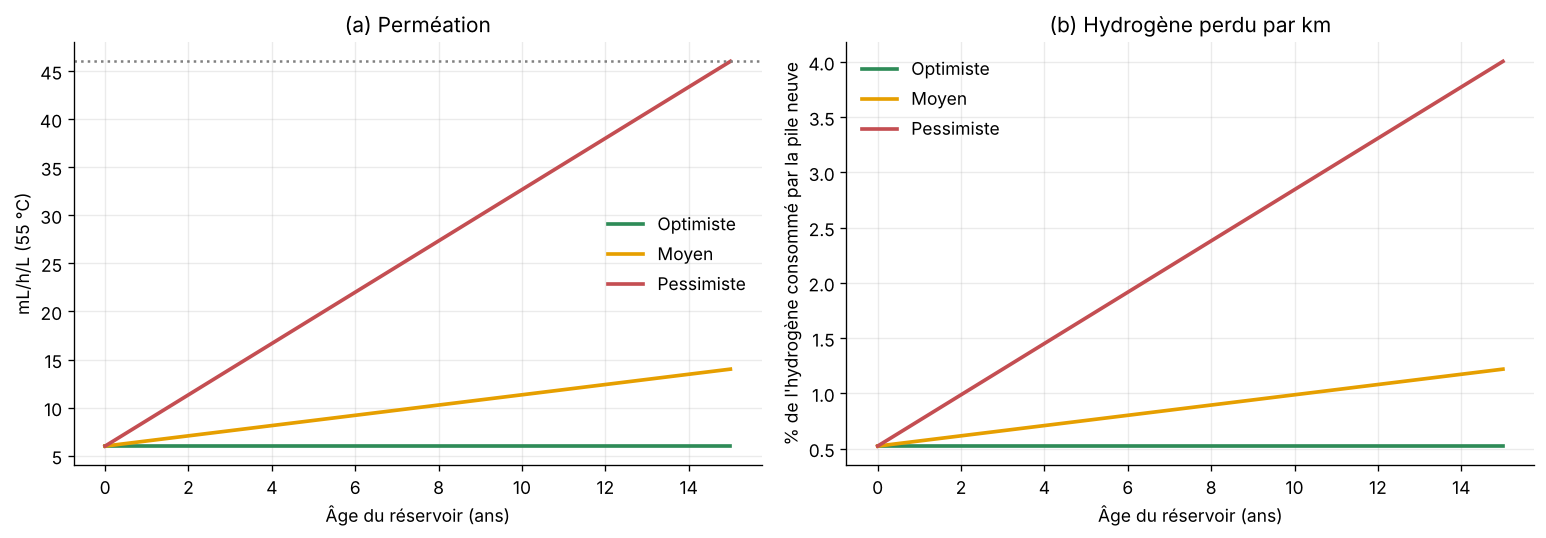

,Perméation à 15 ans (mL/h/L),Perte à 15 ans (g/jour),Perte moyenne sur 15 ans (g/km),Perte moyenne (% de m_FC neuf)
Optimiste,6.000,1.840,0.050,0.522
Moyen,13.999,4.294,0.084,0.871
Pessimiste,45.997,14.109,0.218,2.264


In [7]:
V_RES=142.2;RHO_N=8.988e-8;KM_AN=200000./15.;L_RES=15.   # L ; kg/NmL ; km/an ; ans
RES_SCEN={"Optimiste":(6.,6.),"Moyen":(6.,14.),"Pessimiste":(6.,46.)}
def perm_P(t,sc):
 P0,P1=RES_SCEN[sc] if isinstance(sc,str) else sc;t=np.asarray(t,float);tt=np.mod(t,L_RES);tt=np.where((tt==0)&(t>0),L_RES,tt)   # fin de certification incluse
 return P0+(P1-P0)*tt/L_RES
def perm_km(t,sc):return perm_P(t,sc)*V_RES*RHO_N*8760./KM_AN   # kg H2/km
M0=FC_H2EXP0/DIST
t=np.linspace(0,15,151);fig,axs=plt.subplots(1,2,figsize=(13,4.6))
for sc,c in zip(RES_SCEN,["#2E8B57","#E69F00","#C44E52"]):
 axs[0].plot(t,perm_P(t,sc),color=c,lw=2.2,label=sc);axs[1].plot(t,100*perm_km(t,sc)/M0,color=c,lw=2.2,label=sc)
axs[0].axhline(46,color="grey",ls=":");axs[0].set(xlabel="Âge du réservoir (ans)",ylabel="mL/h/L (55 °C)",title="(a) Perméation");axs[0].legend(frameon=False)
axs[1].set(xlabel="Âge du réservoir (ans)",ylabel="% de l'hydrogène consommé par la pile neuve",title="(b) Hydrogène perdu par km");axs[1].legend(frameon=False)
fig.tight_layout();fig.savefig(OUT/"FAB_01_reservoir.png",dpi=220);plt.show()
res_tab=pd.DataFrame({sc:{"Perméation à 15 ans (mL/h/L)":perm_P(14.999,sc),"Perte à 15 ans (g/jour)":1000*perm_P(14.999,sc)*V_RES*RHO_N*24,
 "Perte moyenne sur 15 ans (g/km)":1000*trapz(perm_km(t,sc),t)/15,"Perte moyenne (% de m_FC neuf)":100*trapz(perm_km(t,sc),t)/15/M0} for sc in RES_SCEN}).T
display(res_tab.round(3))


## 3. Trajectoire sur la vie du véhicule (cas central)

À chaque instant $t$ (années) : âge de la pile $463\,t$ modulo sa fin de vie (remplacement), âge de l'électrolyseur $6\,000\,t$ modulo sa fin de vie, âge du réservoir $t$. Pour gagner du temps, la consommation de la pile est calculée sur une vie de stack puis interpolée.


In [8]:
P_NOM_WE=1250.          # kW : puissance nominale du stack Nel MC250 (NLR, 1,25 MW)
S_WE=1.0                # V14 : l'inventaire (activité peml) est déjà celui du stack de 1,25 MW ; ancien facteur P_NOM_WE/1000     # échelle de l'inventaire (établi pour 1 MW) = puissance nominale / 1 MW
L_VEH=15.;HWE_AN=6000.
_cache={}
def pile_tab(pf,n=61):
 k=("FC",tuple(sorted(pf.items())),n)
 if k not in _cache:
  Tf=fc_eol(pf);a=np.linspace(0,Tf,n);_cache[k]=(Tf,a,np.array([fc_state(x,pf)["H2"] for x in a])/DIST)
 return _cache[k]
def we_tab(pw,n=801):
 k=("WE",tuple(sorted(pw.items())),n)
 if k not in _cache:
  Tw=we_eol(pw);b=np.linspace(0,Tw,n);q=we_state(b,pw)
  _cache[k]=(Tw,b,np.asarray(q["SEC"],float),trapz(np.asarray(q["H2"],float),b)/4.0)   # kg H2 net produits sur la vie
 return _cache[k]
FEv=FE.reindex(IND).to_numpy();EAUv=EAU.reindex(IND).to_numpy();C3v=COMP3.reindex(IND).to_numpy()
def ikg_vec(sec,loss=0,comp=E_COMP,cf=1):return (np.asarray(sec)[:,None]*FEv*cf+EAUv+C3v*comp/3)/(1-loss)
def we_h2_horizon(pw,heures):
 """Hydrogène produit par l'électrolyseur sur l'horizon (kg), stacks successifs repartant de l'état initial."""
 Tw,b,sectab,H2vie=we_tab(pw);nfull=int(heures//Tw);rem=heures-nfull*Tw
 if rem<=0:return nfull*H2vie
 x=np.linspace(0,rem,401);return nfull*H2vie+trapz(np.asarray(we_state(x,pw)["H2"],float),x)/4.0
def vie_vehicule(pf=FC_CENTRAL,pw=WE_CENTRAL,res="Moyen",hwe=HWE_AN,decal=0.,L=L_VEH,s_we=S_WE,discret=True,loss=0,comp=E_COMP,cf=1,npa=80):
 Tf,a,mtab=pile_tab(pf);Tw,b,sectab,H2vie=we_tab(pw)
 t=np.linspace(0,L,int(L*npa)+1);afc=np.mod(t*HFC_AN,Tf);awe=np.mod((t+decal)*hwe,Tw)
 m=np.interp(afc,a,mtab);mp=perm_km(t,res);mt=m+mp;sec=np.interp(awe,b,sectab);ikg=ikg_vec(sec,loss,comp,cf)
 usage=trapz(mt[:,None]*ikg,t,axis=0)/L
 Lkm=L*KM_AN;km_stack=Tf/HFC_AN*KM_AN
 nfc=np.ceil(Lkm/km_stack-1e-9) if discret else Lkm/km_stack   # nombre entier de stacks par défaut (stacks réellement fabriqués)
 nres=np.ceil(L/L_RES-1e-9);mbar=trapz(mt,t)/L
 heures_we=L*hwe;nwe=np.ceil(heures_we/Tw-1e-9) if discret else heures_we/Tw;H2hor=we_h2_horizon(pw,heures_we)
 parts={"Usage":usage,
  "Stacks de pile":nfc*F_STACK_FC.to_numpy()/Lkm,
  "Réservoir":nres*F_RES.to_numpy()/Lkm,
  "Stacks d'électrolyseur":mbar/(1-loss)*s_we*nwe*F_STACK_WE.to_numpy()/H2hor}
 parts={k:pd.Series(v,index=IND) for k,v in parts.items()}
 return {"t":t,"m":m,"mp":mp,"sec":sec,"ikm":mt[:,None]*ikg,"parts":parts,"total":sum(parts.values()),"n_FC":nfc,"km_stack":km_stack,
         "T_FC":Tf,"T_WE":Tw,"H2vie_WE":H2vie,"rempl_WE":int(((L+decal)*hwe)//Tw),"n_WE":nwe,"n_res":nres}
def reference(res="Moyen",hwe=HWE_AN,L=L_VEH,s_we=S_WE,loss=0,comp=E_COMP,cf=1):
 t=np.linspace(0,L,int(L*80)+1);mp=perm_km(t,(RES_SCEN[res][0],)*2);mt=M0+mp;ikg=ikg_vec([WE_SEC0],loss,comp,cf)[0]
 Lkm=L*KM_AN;mbar=trapz(mt,t)/L;H2ref=WE_H20/4.0*hwe*L
 parts={"Usage":mbar*ikg,"Stacks de pile":F_STACK_FC.to_numpy()/Lkm,
  "Réservoir":np.ceil(L/L_RES-1e-9)*F_RES.to_numpy()/Lkm,"Stacks d'électrolyseur":mbar/(1-loss)*s_we*F_STACK_WE.to_numpy()/H2ref}
 parts={k:pd.Series(v,index=IND) for k,v in parts.items()}
 return {"parts":parts,"total":sum(parts.values())}
V=vie_vehicule();REF=reference()
dec=pd.DataFrame({"Avec vieillissement":{k:1000*v[GWP] for k,v in V["parts"].items()},"Sans vieillissement":{k:1000*v[GWP] for k,v in REF["parts"].items()}})
dec.loc["Total"]=dec.sum();dec["Écart (g/km)"]=dec.iloc[:,0]-dec.iloc[:,1]
print(f"Vie du véhicule {L_VEH:.0f} ans = {L_VEH*KM_AN:,.0f} km ; stack de pile : {V['km_stack']:,.0f} km -> {V['n_FC']:.2f} stacks ; électrolyseur : {V['rempl_WE']} remplacement(s) ; H2 produit par stack d'électrolyseur : {V['H2vie_WE']:,.0f} kg")
print("Changement climatique (g CO2-éq/km)");display(dec.round(3))
print(f"Total : {1000*V['total'][GWP]:.2f} g/km avec vieillissement contre {1000*REF['total'][GWP]:.2f} sans (+{100*(V['total'][GWP]/REF['total'][GWP]-1):.1f} %) ; fabrication = {100*(1-V['parts']['Usage'][GWP]/V['total'][GWP]):.0f} % du total")


Vie du véhicule 15 ans = 200,000 km ; stack de pile : 137,831 km -> 2.00 stacks ; électrolyseur : 1 remplacement(s) ; H2 produit par stack d'électrolyseur : 613,632 kg
Changement climatique (g CO2-éq/km)


,Avec vieillissement,Sans vieillissement,Écart (g/km)
Usage,49.069,43.649,5.419
Stacks de pile,36.983,18.492,18.492
Réservoir,11.660,11.660,0.000
Stacks d'électrolyseur,0.682,0.322,0.360
Total,98.394,74.123,24.271


Total : 98.39 g/km avec vieillissement contre 74.12 sans (+32.7 %) ; fabrication = 50 % du total


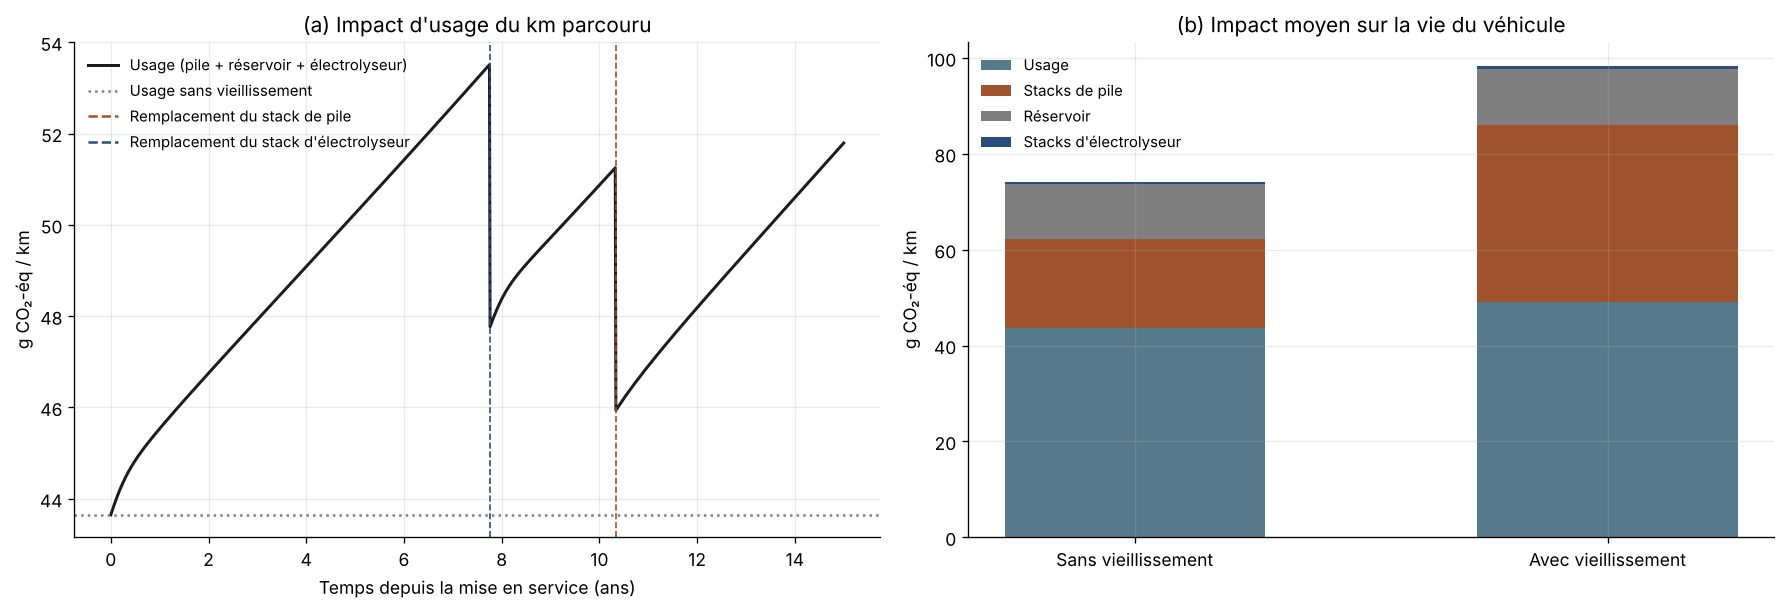

In [9]:
t=V["t"];G=IND.index(GWP)
fig,axs=plt.subplots(1,2,figsize=(15,5.2))
axs[0].plot(t,1000*V["ikm"][:,G],color="#1C1C1C",lw=1.8,label="Usage (pile + réservoir + électrolyseur)")
axs[0].axhline(1000*REF["parts"]["Usage"][GWP],color="grey",ls=":",label="Usage sans vieillissement")
for k in range(1,int(np.ceil(V["n_FC"]))):axs[0].axvline(k*V["T_FC"]/HFC_AN,color="#A0522D",ls="--",lw=1)
for k in range(1,V["rempl_WE"]+1):axs[0].axvline(k*V["T_WE"]/HWE_AN,color="#2B4C7E",ls="--",lw=1)
axs[0].plot([],[],color="#A0522D",ls="--",label="Remplacement du stack de pile");axs[0].plot([],[],color="#2B4C7E",ls="--",label="Remplacement du stack d'électrolyseur")
axs[0].set(xlabel="Temps depuis la mise en service (ans)",ylabel="g CO₂-éq / km",title="(a) Impact d'usage du km parcouru");axs[0].legend(frameon=False,fontsize=9,loc="upper left")
order=["Usage","Stacks de pile","Réservoir","Stacks d'électrolyseur"]
cols=["#567A8C","#A0522D","#7F7F7F","#2B4C7E"];x=np.arange(2);bot=np.zeros(2)
for k,c in zip(order,cols):
 v=np.array([1000*REF["parts"][k][GWP],1000*V["parts"][k][GWP]]);axs[1].bar(x,v,bottom=bot,color=c,label=k,width=.55);bot+=v
axs[1].set_xticks(x,["Sans vieillissement","Avec vieillissement"]);axs[1].set(ylabel="g CO₂-éq / km",title="(b) Impact moyen sur la vie du véhicule");axs[1].legend(frameon=False,fontsize=9,loc="upper left")
fig.tight_layout();fig.savefig(OUT/"FAB_02_vie_vehicule.png",dpi=220);plt.show()


### 16 indicateurs

Hausse due au vieillissement (fabrication et remplacements compris) et part de la fabrication, cas central.

,Sans vieillissement,Avec vieillissement,Hausse_pct,Part Usage (%),Part Stacks de pile (%),Part Réservoir (%),Part Stacks d'électrolyseur (%)
Acidification,0.001,0.003,86.981,5.931,91.365,2.361,0.344
Changement climatique,0.074,0.098,32.745,49.869,37.587,11.850,0.693
Écotoxicité totale,0.491,0.844,71.883,12.441,80.526,6.619,0.413
Écotoxicité inorganique,0.483,0.834,72.575,12.325,81.022,6.242,0.411
Écotoxicité organique,0.008,0.010,30.167,21.697,40.915,36.774,0.615
Énergie fossile,8.151,9.433,15.721,91.317,6.889,1.699,0.095
Eutrophisation eau douce,0.000,0.000,70.063,12.743,78.842,7.712,0.703
Eutrophisation marine,0.000,0.000,60.534,24.877,69.493,5.226,0.404
Eutrophisation terrestre,0.002,0.003,74.642,13.652,82.047,3.905,0.396
Toxicité humaine totale,0.000,0.000,38.850,45.385,43.613,8.777,2.225


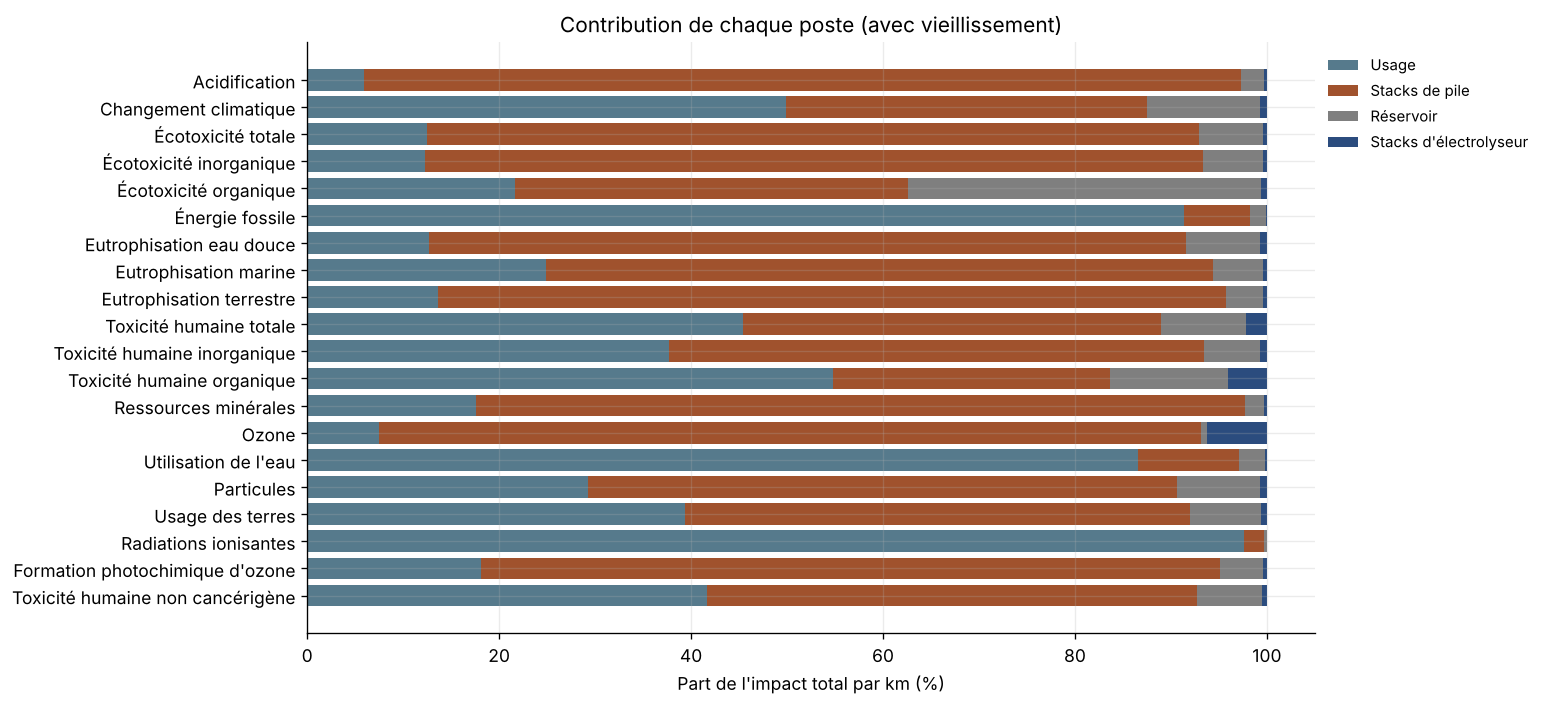

In [10]:
tab16=pd.DataFrame({"Sans vieillissement":REF["total"],"Avec vieillissement":V["total"]})
tab16["Hausse_pct"]=100*(tab16.iloc[:,1]/tab16.iloc[:,0]-1)
for k in order:tab16[f"Part {k} (%)"]=100*V["parts"][k]/V["total"]
display(tab16.round(3))
fig,ax=plt.subplots(figsize=(13,6));left=np.zeros(len(IND))
for k,c in zip(order,cols):
 v=100*(V["parts"][k]/V["total"]).to_numpy();ax.barh(IND,v,left=left,color=c,label=k);left+=v
ax.set(xlabel="Part de l'impact total par km (%)",title="Contribution de chaque poste (avec vieillissement)");ax.invert_yaxis();ax.legend(frameon=False,fontsize=9,bbox_to_anchor=(1,1))
fig.tight_layout();fig.savefig(OUT/"FAB_03_16_indicateurs.png",dpi=220);plt.show()


## 4. Scénarios de vieillissement

La fabrication change le classement des scénarios : une pile qui s'use vite demande plus de stacks.

,Pile,Électrolyseur,Stacks pile,Usage (g/km),Fabrication (g/km),Total (g/km),Hausse_pct
0,Optimiste,Optimiste,1.0,48.72,30.83,79.56,7.33
1,Optimiste,Moyen,1.0,49.15,30.83,79.99,7.91
2,Optimiste,Pessimiste,1.0,49.13,31.18,80.30,8.34
3,Moyen,Optimiste,2.0,48.69,49.33,98.01,32.23
4,Moyen,Moyen,2.0,49.07,49.33,98.39,32.75
5,Moyen,Pessimiste,2.0,49.06,49.67,98.72,33.19
6,Pessimiste,Optimiste,2.0,49.32,49.33,98.65,33.09
7,Pessimiste,Moyen,2.0,49.78,49.33,99.12,33.72
8,Pessimiste,Pessimiste,2.0,49.72,49.68,99.40,34.10


Électrolyseur,Optimiste,Moyen,Pessimiste
Pile \ Électrolyseur,,,
Optimiste,7.3,7.9,8.3
Moyen,32.2,32.7,33.2
Pessimiste,33.1,33.7,34.1


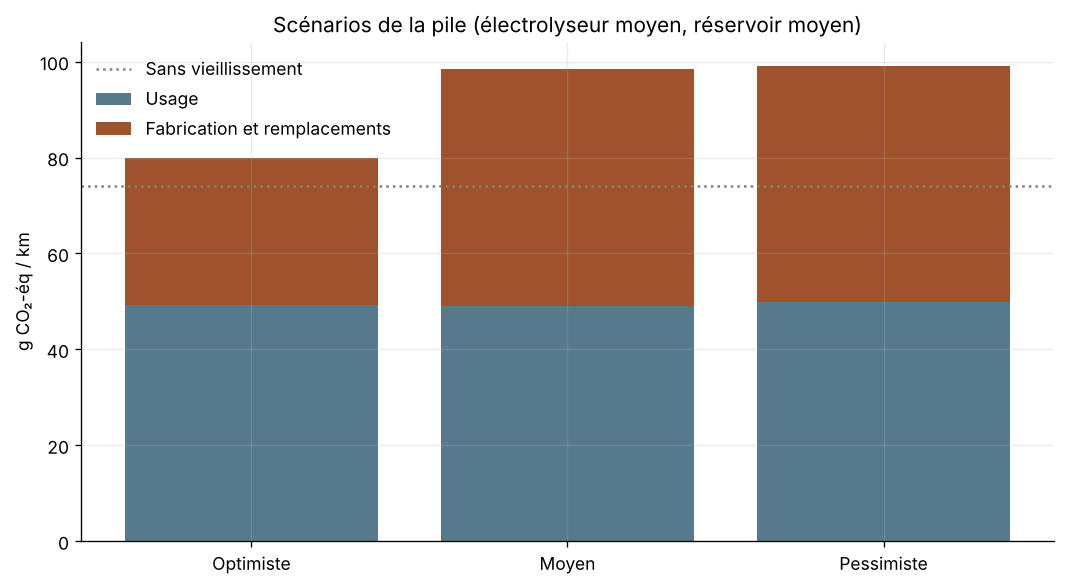

In [11]:
rows=[]
for nf,pf in FC_SCEN.items():
 for nw,pw in WE_SCEN.items():
  v=vie_vehicule(pf,pw);rows.append({"Pile":nf,"Électrolyseur":nw,"Stacks pile":v["n_FC"],"Usage (g/km)":1000*v["parts"]["Usage"][GWP],
   "Fabrication (g/km)":1000*(v["total"][GWP]-v["parts"]["Usage"][GWP]),"Total (g/km)":1000*v["total"][GWP],"Hausse_pct":100*(v["total"][GWP]/REF["total"][GWP]-1)})
scen=pd.DataFrame(rows);display(scen.round(2))
mat=scen.pivot(index="Pile",columns="Électrolyseur",values="Hausse_pct").loc[list(FC_SCEN),list(WE_SCEN)];mat.index.name="Pile \\ Électrolyseur";display(mat.round(1))
fig,ax=plt.subplots(figsize=(9,5));q=scen[scen["Électrolyseur"]=="Moyen"].set_index("Pile").loc[list(FC_SCEN)]
ax.bar(q.index,q["Usage (g/km)"],color="#567A8C",label="Usage");ax.bar(q.index,q["Fabrication (g/km)"],bottom=q["Usage (g/km)"],color="#A0522D",label="Fabrication et remplacements")
ax.axhline(1000*REF["total"][GWP],color="grey",ls=":",label="Sans vieillissement")
ax.set(ylabel="g CO₂-éq / km",title="Scénarios de la pile (électrolyseur moyen, réservoir moyen)");ax.legend(frameon=False)
fig.tight_layout();fig.savefig(OUT/"FAB_04_scenarios.png",dpi=220);plt.show()


### 4 bis. Effet de la loi de crossover sur la chaîne complète

Trois lois calées sur la même mesure de Colombo et al. (facteur 1,4 ou 2,6 en 1 000 h) : linéaire (centrale), exponentielle (Jouin et al., 2016), constante (crossover stable mesuré par Toyota, Takahashi et al., IJHE 2022). Pile, électrolyseur et réservoir sont pris dans le même scénario. La fin de vie de la pile (tension) ne dépend pas de la loi.


In [12]:
LOIS={"lineaire":"Linéaire (centrale)","exponentielle":"Exponentielle (Jouin)","constant":"Constante (Toyota)"}
_f0=FC_FORME_X;rows=[]
for forme,lab in LOIS.items():
 FC_FORME_X=forme;_cache.clear()
 for nf,pf in FC_SCEN.items():
  v=vie_vehicule(pf,WE_SCEN[nf],res=nf)
  rows.append({"Loi":lab,"Scénario":nf,"Stacks pile":v["n_FC"],"Crossover fin de vie (mA/cm²)":1e3*float(fc_crossover(v["T_FC"],pf)),
               "Total (g/km)":1000*v["total"][GWP],"Hausse_pct":100*(v["total"][GWP]/REF["total"][GWP]-1)})
FC_FORME_X=_f0;_cache.clear()
lois=pd.DataFrame(rows);display(lois.round(2))
display(lois.pivot(index="Loi",columns="Scénario",values="Hausse_pct").loc[list(LOIS.values()),list(FC_SCEN)].round(1))
lois.to_csv(OUT/"FAB_lois_crossover.csv",index=False,encoding="utf-8-sig")


,Loi,Scénario,Stacks pile,Crossover fin de vie (mA/cm²),Total (g/km),Hausse_pct
0,Linéaire (centrale),Optimiste,1.0,6.65,79.40,7.11
1,Linéaire (centrale),Moyen,2.0,8.95,98.39,32.75
2,Linéaire (centrale),Pessimiste,2.0,11.26,100.06,34.99
3,Exponentielle (Jouin),Optimiste,1.0,14.12,80.05,8.00
4,Exponentielle (Jouin),Moyen,2.0,23.71,99.31,33.98
5,Exponentielle (Jouin),Pessimiste,2.0,31.78,101.49,36.93
6,Constante (Toyota),Optimiste,1.0,2.00,78.51,5.92
7,Constante (Toyota),Moyen,2.0,2.00,97.24,31.18
8,Constante (Toyota),Pessimiste,2.0,2.00,98.26,32.56


Scénario,Optimiste,Moyen,Pessimiste
Loi,,,
Linéaire (centrale),7.1,32.7,35.0
Exponentielle (Jouin),8.0,34.0,36.9
Constante (Toyota),5.9,31.2,32.6


## 5. Sensibilité aux hypothèses F1 à F9

In [13]:
base=1000*V["total"][GWP];rows=[]
def add(h,val,**kw):
 v=vie_vehicule(**kw);r=reference(**{k:kw[k] for k in kw if k in ("res","hwe","L","s_we")})
 rows.append({"Hypothèse":h,"Valeur":val,"Total (g/km)":1000*v["total"][GWP],"Écart au central (%)":100*(1000*v["total"][GWP]/base-1),"Hausse due au vieillissement (%)":100*(v["total"][GWP]/r["total"][GWP]-1),"Stacks pile":v["n_FC"]})
for L in [10.,15.,20.]:add("F1 : vie du véhicule",f"{L:.0f} ans",L=L)
add("F2-F3 : stacks de pile et d'électrolyseur","répartition continue",discret=False)
for s in [S_WE,P_WE/P_NOM_WE,1000./P_NOM_WE]:add("F4 : échelle de l'inventaire électrolyseur",f"s = {s:.2f}",s_we=s)
for sc in RES_SCEN:add("F6 : réservoir",sc,res=sc)
for h in [4000.,8000.]:add("F9 : heures de l'électrolyseur",f"{h:.0f} h/an",hwe=h)
for d in [2.,4.]:add("F9 : électrolyseur mis en service avant",f"{d:.0f} ans",decal=d)
sens=pd.DataFrame(rows);display(sens.round(2))


,Hypothèse,Valeur,Total (g/km),Écart au central (%),Hausse due au vieillissement (%),Stacks pile
0,F1 : vie du véhicule,10 ans,95.31,-3.14,6.66,1.00
1,F1 : vie du véhicule,15 ans,98.39,0.00,32.75,2.00
2,F1 : vie du véhicule,20 ans,95.24,-3.21,26.56,2.00
3,F2-F3 : stacks de pile et d'électrolyseur,répartition continue,88.22,-10.34,19.02,1.45
4,F4 : échelle de l'inventaire électrolyseur,s = 1.00,98.39,0.00,32.75,2.00
5,F4 : échelle de l'inventaire électrolyseur,s = 0.57,98.10,-0.30,32.60,2.00
6,F4 : échelle de l'inventaire électrolyseur,s = 0.80,98.26,-0.14,32.68,2.00
7,F6 : réservoir,Optimiste,98.23,-0.17,32.52,2.00
8,F6 : réservoir,Moyen,98.39,0.00,32.75,2.00
9,F6 : réservoir,Pessimiste,99.05,0.67,33.63,2.00


## 6. Monte-Carlo

Mêmes lois que le notebook de couplage, plus la perméation du réservoir en fin de certification ($P_{15}$ uniforme entre 6 et 46 mL/h/L) et la vie du véhicule (uniforme entre 10 et 20 ans). 300 tirages.

,Analyse,Sortie,P5,Médiane,P95
0,Vie du véhicule,Total_g_km,89.35,106.04,120.02
1,Vie du véhicule,Usage_g_km,44.26,50.11,56.51
2,Vie du véhicule,Part_fabrication_pct,44.12,52.66,59.26
3,Vie du véhicule,Hausse_vieillissement_pct,8.02,31.17,46.21
4,Vie du véhicule,Stacks_pile,1.00,2.00,3.00


,Entrée,Rho total,Rho hausse
2,fc_k_R,0.530,0.587
9,CF_electricite,0.354,-0.164
3,fc_k_mem,0.131,0.179
11,Vie_vehicule_ans,-0.129,-0.156
10,P15_reservoir,0.088,0.100
6,we_t50,0.068,0.054
8,Compression,0.056,-0.014
1,fc_S1000,0.044,0.010
7,Heures_WE_an,0.033,0.116
5,we_fA_min,0.021,-0.006


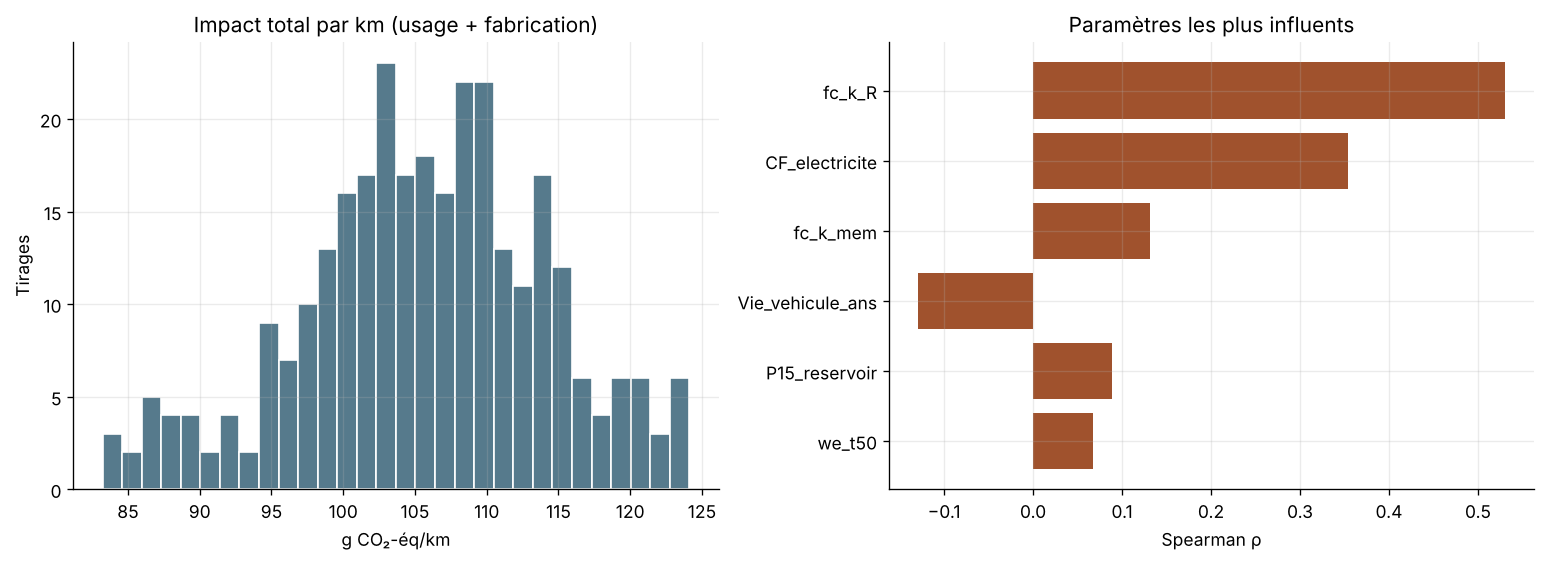

In [14]:
rng=np.random.default_rng(47);NMC=300
cin=pd.DataFrame({"fc_omega":rng.uniform(*FC_BOUNDS["omega"],NMC),"fc_S1000":rng.uniform(*FC_BOUNDS["S1000"],NMC),
"fc_k_R":rng.uniform(*FC_BOUNDS["k_R"],NMC),"fc_k_mem":rng.uniform(*FC_BOUNDS["k_mem"],NMC),
"we_k_R":rng.uniform(PADGETT["dHFR"],PADGETT["dHFR"]+PADGETT["dCLR"],NMC)/WE_R0,
"we_fA_min":rng.uniform(PADGETT["fA_masse"],PADGETT["fA_capa"],NMC),
"we_t50":rng.uniform(CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"],NMC),
"Heures_WE_an":rng.triangular(4000,6000,8000,NMC),"Compression":rng.triangular(2,3,5,NMC),"CF_electricite":rng.triangular(.8,1,1.2,NMC),
"P15_reservoir":rng.uniform(6,46,NMC),"Vie_vehicule_ans":rng.uniform(10,20,NMC)})
out=[]
for _,r0 in cin.iterrows():
 pf=FC_CENTRAL.copy();pw=WE_CENTRAL.copy()
 pf.update({"omega":r0.fc_omega,"S1000":r0.fc_S1000,"k_R":r0.fc_k_R,"k_mem":r0.fc_k_mem});pw.update({"k_R":r0.we_k_R,"fA_min":r0.we_fA_min,"t50_mem":r0.we_t50})
 kw=dict(res=(6.,r0.P15_reservoir),hwe=r0.Heures_WE_an,L=r0.Vie_vehicule_ans,comp=r0.Compression,cf=r0.CF_electricite)
 v=vie_vehicule(pf,pw,npa=40,**kw)
 rv=reference(res="Optimiste",hwe=r0.Heures_WE_an,L=r0.Vie_vehicule_ans,comp=r0.Compression,cf=r0.CF_electricite)
 out.append({"Total_g_km":1000*v["total"][GWP],"Usage_g_km":1000*v["parts"]["Usage"][GWP],"Part_fabrication_pct":100*(1-v["parts"]["Usage"][GWP]/v["total"][GWP]),
             "Hausse_vieillissement_pct":100*(v["total"][GWP]/rv["total"][GWP]-1),"Stacks_pile":v["n_FC"]})
mc=pd.concat([cin,pd.DataFrame(out)],axis=1)
mc_sum=percentiles(mc,["Total_g_km","Usage_g_km","Part_fabrication_pct","Hausse_vieillissement_pct","Stacks_pile"],"Vie du véhicule");display(mc_sum.round(2))
rho=pd.DataFrame([{"Entrée":x,"Rho total":spearmanr(mc[x],mc.Total_g_km).statistic,"Rho hausse":spearmanr(mc[x],mc.Hausse_vieillissement_pct).statistic} for x in cin]).sort_values("Rho total",key=abs,ascending=False)
display(rho.round(3))
fig,axs=plt.subplots(1,2,figsize=(13,4.8))
axs[0].hist(mc.Total_g_km,bins=30,color="#567A8C",edgecolor="white");axs[0].set(xlabel="g CO₂-éq/km",ylabel="Tirages",title="Impact total par km (usage + fabrication)")
r=rho.head(6);axs[1].barh(r["Entrée"],r["Rho total"],color="#A0522D");axs[1].invert_yaxis();axs[1].set(xlabel="Spearman ρ",title="Paramètres les plus influents")
fig.tight_layout();fig.savefig(OUT/"FAB_05_MonteCarlo.png",dpi=220);plt.show()


## 7. Contrôles et export

In [15]:
checks={"Usage sur la vie du véhicule proche du couplage sur la vie de la pile (48,81 g/km, ±3 %)":abs(1000*V["parts"]["Usage"][GWP]/48.81-1)<.03,
"Fabrication > 0 pour les 16 indicateurs":bool((V["total"]>V["parts"]["Usage"]).all()),
"Pile pessimiste la plus impactante (fabrication comprise)":bool(mat.loc["Pessimiste"].min()>mat.loc["Optimiste"].max()),
"Somme des postes = total":bool(np.allclose(sum(V["parts"].values()),V["total"])),
"Monte-Carlo fini":bool(np.isfinite(mc.Total_g_km).all())}
display(pd.DataFrame({"Contrôle":checks.keys(),"OK":checks.values()}));assert all(checks.values())
tabfab.to_csv(OUT/"FAB_impacts_fabrication.csv",encoding="utf-8-sig");res_tab.to_csv(OUT/"FAB_reservoir.csv",encoding="utf-8-sig")
dec.to_csv(OUT/"FAB_decomposition_climat.csv",encoding="utf-8-sig");tab16.to_csv(OUT/"FAB_16_indicateurs.csv",encoding="utf-8-sig")
scen.to_csv(OUT/"FAB_scenarios.csv",index=False,encoding="utf-8-sig");sens.to_csv(OUT/"FAB_sensibilite.csv",index=False,encoding="utf-8-sig")
mc.to_csv(OUT/"FAB_MonteCarlo.csv",index=False,encoding="utf-8-sig")
print("Notebook fabrication validé. Résultats :",OUT.resolve())


,Contrôle,OK
0,"Usage sur la vie du véhicule proche du couplage sur la vie de la pile (48,81 g/km, ±3 %)",True
1,Fabrication > 0 pour les 16 indicateurs,True
2,Pile pessimiste la plus impactante (fabrication comprise),True
3,Somme des postes = total,True
4,Monte-Carlo fini,True


Notebook fabrication validé. Résultats : ./resultats_fabrication


## 8. Limites

| Limite | Effet | Traitement |
|---|---|---|
| Auxiliaires (BOP) hors périmètre | le total par km est sous-estimé ; l'effet du vieillissement n'est pas modifié, car les BOP ne sont pas remplacés | périmètre explicite (F5) |
| Inventaire du stack d'électrolyseur établi pour 1 MW, mis à l'échelle linéairement à 1,25 MW | change la part de l'électrolyseur | $s$ de 0,71 à 1,25 |
| Perméation : pas de loi publiée ; interpolation entre valeur neuve et limite réglementaire | majorant (55 °C, réservoir plein) | trois scénarios, Monte-Carlo |
| Hydrogène perméé non caractérisé (effet de serre indirect de H₂) | sous-estime le climat | limite de la méthode EF 3.1 |
| Fin de vie des équipements (recyclage du platine, de l'iridium, du titane) non comptée | surestime probablement la fabrication | perspective |
| Vie du véhicule liée à la certification du réservoir | fixe le nombre de stacks | 10 à 20 ans testés |
